<a href="https://colab.research.google.com/github/all3048/Beginning-Bioinformatics/blob/main/Real_Gut_to_Soil_QIIME2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gut-to-soil microbiome analysis

Name: **Ana Ledesma** &nbsp; Date: **10/30/2026**

Follow the [Gut-to-soil tutorial, release 2026.10](https://gut-to-soil-tutorial.readthedocs.io/en/2026.10/). Use its **Command Line** tabs.

Your goal is to turn paired-end 16S reads into a community profile, compare environments, and connect the analysis to machine learning.

### How to use this notebook
1. Run the three **Provided setup** sections unchanged.
2. Work through the tutorial and notebook together, one cell at a time. Do **not** use Run all while placeholders remain.
3. For each numbered task, copy the indicated `qiime ...` command from the tutorial's **Command Line** tab and paste it **between** the triple quotes, replacing `PASTE_TUTORIAL_COMMAND_HERE`. Include its option lines and backslashes. Do not paste Markdown fences, `$`, `!`, `cd`, or the Python API example.
4. Keep tutorial filenames. The provided `tutorial_step` function runs the command in the installed QIIME environment and correct directory. You do not need to activate an environment or add `!`.
5. Use the visualization selector after each section to download `.qzv` outputs; open them in [QIIME 2 View](https://view.qiime2.org/). Write observations in the response cells.
6. Save your notebook with responses and download the results ZIP at the end.

One **"Worked example"** is included before the first task. Blank cells stop with a clear message rather than running an answer for you.


### Colab adjustments handled for you
The adapter prints the final command before running it. It limits DADA2 threads, taxonomy-training batch size, and taxonomy-classification workers/batches. It saves the classifier annotation to a separate file and uses that annotated copy downstream. Provenance paths are adjusted to this notebook's folder. All biological settings remain those in your pasted command. Reference artifacts and input reads are provided by download helpers so the exercise focuses on analytical commands.


## Provided setup A — Settings and file helpers

Keep the release fixed. The configuration records downloaded-file checksums and the installed environment. The release environment is pinned by its published specification; its URL is not a content-addressed lockfile. Downloads and generated results live on the Colab VM until you export them.

If you change an analysis parameter, rerun that cell and every downstream cell. The runner detects changed inputs/commands and recomputes outputs. The student tasks compute DADA2; the recovery section provides separately labeled reference plots if needed.


In [7]:
from pathlib import Path
import os, sys, json, shlex, shutil, subprocess, hashlib, time, urllib.request
import tarfile, zipfile, platform, html

RELEASE = "2026.10"
DADA2_MODE = "compute"             # "compute" or "checkpoint"
REFERENCE_SOURCE = "tutorial-artifacts"  # or "rebuild" (download from GTDB)
THREADS = 2
TRAINING_CHUNK_SIZE = 200          # tutorial uses 2000; smaller lowers transient RAM
SAMPLING_DEPTH = 96                # shallow tutorial subset, not a research recommendation
RAREFACTIONS = 10
SEED = 42
assert DADA2_MODE in {"compute", "checkpoint"}
assert REFERENCE_SOURCE in {"tutorial-artifacts", "rebuild"}
assert platform.system() == "Linux" and platform.machine() in {"x86_64", "AMD64"}

ROOT = Path('/content/gut_to_soil_student')
WORK = ROOT / 'analysis'
LOGS = ROOT / 'logs'
for p in (ROOT, WORK, LOGS): p.mkdir(parents=True, exist_ok=True)
MM = ROOT / 'bin' / 'micromamba'
PREFIX = ROOT / ('qiime-' + RELEASE)
BASE = f'https://gut-to-soil-tutorial.readthedocs.io/en/{RELEASE}/data/gut-to-soil/'
ENV_URL = f'https://raw.githubusercontent.com/qiime2/distributions/refs/heads/dev/{RELEASE}/qiime2/released/rachis-qiime2-linux-64-conda.yml'
RUN_ENV = os.environ.copy()
# Prevent notebook-side Python settings from leaking into the QIIME process.
for key in ('PYTHONPATH', 'PYTHONHOME'): RUN_ENV.pop(key, None)
RUN_ENV.update(MAMBA_ROOT_PREFIX=str(ROOT / 'mamba'), PYTHONNOUSERSITE='1',
               MPLBACKEND='Agg', OMP_NUM_THREADS=str(THREADS),
               OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1')

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()

def record(name, item):
    p = ROOT / name
    data = json.loads(p.read_text()) if p.exists() else []
    data.append(dict(time=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()), **item))
    p.write_text(json.dumps(data, indent=2))

def download(url, dest, *, refresh=False):
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size and not refresh:
        return dest
    temp = dest.with_name(dest.name + '.part')
    for attempt in range(3):
        try:
            req = urllib.request.Request(url, headers={'User-Agent':'GutToSoilTeachingNotebook/1.0'})
            with urllib.request.urlopen(req, timeout=120) as response, temp.open('wb') as out:
                shutil.copyfileobj(response, out)
            if not temp.stat().st_size: raise ValueError('Empty download')
            if dest.suffix in {'.qza', '.qzv', '.zip'}:
                if not zipfile.is_zipfile(temp): raise ValueError('Expected ZIP/QIIME artifact; got another file type')
                with zipfile.ZipFile(temp) as z:
                    bad = z.testzip()
                    if bad: raise ValueError('Corrupt ZIP member: '+bad)
            elif dest.suffix in {'.tsv', '.yml'}:
                beginning = temp.read_text()[:200].lower()
                if '<html' in beginning or '<!doctype' in beginning:
                    raise ValueError('Received an HTML page instead of data')
            temp.replace(dest)
            record('downloads.json', dict(url=url, path=str(dest.relative_to(ROOT)),
                   bytes=dest.stat().st_size, sha256=sha256(dest)))
            print('Downloaded', dest.name, f'({dest.stat().st_size/1e6:.1f} MB)')
            return dest
        except Exception:
            temp.unlink(missing_ok=True)
            if attempt == 2: raise
            time.sleep(2)

def fetch(name, dest=None):
    return download(BASE + name, WORK / (dest or name))

def run(argv, log_name='command', cwd=None):
    argv = [str(a) for a in argv]
    print('$', shlex.join(argv), flush=True)
    log = LOGS / (log_name + '.log')
    started = time.monotonic()
    with log.open('w') as f:
        p = subprocess.Popen(argv, cwd=cwd or WORK, env=RUN_ENV,
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, bufsize=1)
        try:
            for line in p.stdout:
                print(line, end='', flush=True); f.write(line); f.flush()
            rc = p.wait()
        except BaseException:
            p.terminate()
            try: p.wait(timeout=10)
            except subprocess.TimeoutExpired: p.kill(); p.wait()
            raise
    record('runs.json', dict(command=argv, returncode=rc,
           seconds=round(time.monotonic()-started, 2), log=str(log.relative_to(ROOT))))
    if rc:
        raise RuntimeError(f'Command failed (exit {rc}). Read {log}. No checkpoint was substituted.')

def qcmd(args): return [MM, 'run', '-p', PREFIX, 'qiime', *args]

mem = dict(line.split(':',1) for line in Path('/proc/meminfo').read_text().splitlines())
print('Available RAM:', round(int(mem['MemAvailable'].split()[0])/1024**2,1), 'GiB')
print('Free disk:', round(shutil.disk_usage(ROOT).free/1024**3,1), 'GiB')
print('Notebook Python:', sys.executable, '(will remain unchanged)')


Available RAM: 11.5 GiB
Free disk: 87.1 GiB
Notebook Python: /usr/bin/python3 (will remain unchanged)


## Provided setup B — Installation

This uses the official release environment with micromamba as its Conda-compatible installer. It does not replace Colab's Python. Installation may be lengthy; inspect the live output. If it fails, keep the installation log rather than adding arbitrary `pip install` fixes. The initial free-space check is a conservative classroom guard, not an official minimum.


In [8]:
if not MM.exists():
    package = download('https://micro.mamba.pm/api/micromamba/linux-64/latest', ROOT/'micromamba.tar.bz2')
    with tarfile.open(package) as tar:
        member = tar.getmember('bin/micromamba')
        MM.parent.mkdir(exist_ok=True)
        with tar.extractfile(member) as src, MM.open('wb') as dst:
            shutil.copyfileobj(src, dst)
    MM.chmod(0o755)
run([MM, '--version'], 'micromamba-version')
env_file = download(ENV_URL, ROOT/f'qiime-{RELEASE}.yml')
ready = PREFIX / '.notebook-install-complete'
if not ready.exists():
    if shutil.disk_usage(ROOT).free < 20*1024**3:
        raise RuntimeError('Less than 20 GiB free. Start a fresh runtime or free space before installation.')
    run([MM, 'create', '-y', '-p', PREFIX, '-f', env_file], 'installation')
    run(qcmd(['info']), 'qiime-info')
    ready.write_text(sha256(env_file))
else:
    assert ready.read_text() == sha256(env_file), 'Environment specification changed; use a fresh runtime.'
    run(qcmd(['info']), 'qiime-info')
run([MM, 'list', '-p', PREFIX, '--explicit'], 'environment-explicit')
print('Installation passed qiime info. Next: test the actual tutorial actions.')


Downloaded micromamba.tar.bz2 (7.3 MB)
$ /content/gut_to_soil_student/bin/micromamba --version
2.10.0
Downloaded qiime-2026.10.yml (0.0 MB)
$ /content/gut_to_soil_student/bin/micromamba create -y -p /content/gut_to_soil_student/qiime-2026.10 -f /content/gut_to_soil_student/qiime-2026.10.yml
⚠ Shard Index for https://packages.qiime2.org/qiime2/2026.10/qiime2/released/linux-64 not available, falling back to flat repodata
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...           ✔ Starting
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...     ✔ Done (0.0 sec)
⚠ Shard Index for https://packages.qiime2.org/qiime2/2026.10/qiime2/released/noarch not available, falling back to flat repodata
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...           ✔ Starting
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...     ✔ Done (0.0 sec)
Fetch Shard Index fo

## Provided setup C — Compatibility checks and runner

This checks release-specific command flags before the analysis starts. A successful preflight verifies the CLI, not the analysis itself. Each step writes a success record only after all expected outputs exist. Changed input bytes or changed commands invalidate cached results. Partial outputs are regenerated on retry.


In [9]:
checks = {
 ('dada2','denoise-paired'): ['--o-base-transition-stats','--p-n-threads'],
 ('feature-table','summarize'): ['--o-summary','--o-sample-frequencies','--m-metadata-file'],
 ('feature-table','tabulate-seqs'): ['--i-taxonomy'],
 ('feature-classifier','fit-classifier-naive-bayes'): ['--p-classify--chunk-size'],
 ('feature-classifier','classify-sklearn'): ['--p-reads-per-batch','--p-n-jobs'],
 ('boots','kmer-diversity'): ['--p-n','--p-no-replacement'],
 ('composition','ancombc2'): ['--p-fixed-effects-formula','--o-ancombc2-output'],
 ('composition','da-barplot'): ['--i-data'],
 ('rescript','get-gtdb-data'): ['--p-db-type'],
 ('tools','annotation-create'): ['--annotation-type'],
 ('tools','replay-provenance'): ['--in-fp','--out-fp'],
}
problems=[]
for action, flags in checks.items():
    p = subprocess.run([str(x) for x in qcmd([*action,'--help'])], env=RUN_ENV,
                       text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    (LOGS/('help-'+'-'.join(action)+'.log')).write_text(p.stdout)
    missing=[f for f in flags if f not in p.stdout]
    if p.returncode or missing: problems.append((' '.join(action),missing,p.returncode))
if problems: raise RuntimeError(f'Release/API mismatch: {problems}. See help logs; do not mix tutorial releases.')
print('All tutorial API checks passed.')

def digest_path(p):
    p=Path(p)
    if p.is_file(): return sha256(p)
    if p.is_dir():
        return hashlib.sha256(json.dumps([(str(f.relative_to(p)),sha256(f))
             for f in sorted(p.rglob('*')) if f.is_file()]).encode()).hexdigest()
    return None

def step(name, command, outputs):
    argv=shlex.split(command)
    assert argv[0]=='qiime'
    paths=[WORK/o for o in outputs]
    for p in paths:
        assert p.resolve().is_relative_to(WORK.resolve()) and p.resolve()!=WORK.resolve()
    inputs={}
    for token in argv[1:]:
        candidate=WORK/token
        # Named collection arguments use label:path.
        if not candidate.exists() and ':' in token: candidate=WORK/token.split(':',1)[1]
        if candidate.exists() and candidate not in paths:
            inputs[str(candidate.relative_to(WORK))]=digest_path(candidate)
    signature=hashlib.sha256(json.dumps([command,inputs,RELEASE],sort_keys=True).encode()).hexdigest()
    marker=LOGS/('step-'+hashlib.sha256(name.encode()).hexdigest()[:12]+'.json')
    old=json.loads(marker.read_text()) if marker.exists() else {}
    observed={o:digest_path(WORK/o) for o in outputs}
    if old.get('signature')==signature and all(observed.values()) and old.get('outputs')==observed:
        print('Already completed:',name); return
    marker.unlink(missing_ok=True)
    for p in paths:
        if p.is_dir(): shutil.rmtree(p)
        elif p.exists(): p.unlink()
    run(qcmd(argv[1:]), 'step-'+hashlib.sha256(name.encode()).hexdigest()[:12])
    observed={o:digest_path(WORK/o) for o in outputs}
    if not all(observed.values()): raise RuntimeError(f'Missing outputs for {name}: {observed}')
    marker.write_text(json.dumps(dict(name=name,signature=signature,outputs=observed),indent=2))

def view_outputs():
    from IPython.display import display, HTML
    import ipywidgets as w
    paths=sorted(WORK.rglob('*.qzv'))
    if not paths: print('No visualizations yet.'); return
    choices=w.Dropdown(options=[(str(p.relative_to(WORK)),str(p)) for p in paths],
                       description='Result:',layout=w.Layout(width='90%'))
    button=w.Button(description='Download selected .qzv')
    def selected(_):
        from google.colab import files
        files.download(choices.value)
    button.on_click(selected)
    display(HTML('<p>Download a visualization, then open it at <a href="https://view.qiime2.org/" target="_blank">QIIME 2 View</a>. Inspect its provenance as well as its plots.</p>'))
    display(choices,button)


All tutorial API checks passed.


## Provided setup D — Paste-in adapter
Run once. This accepts a **single QIIME command** per task. It recognizes the requested outputs, applies the Colab adjustments listed above, and passes the command to the tested runner. It does not fill in missing commands or invent results.


In [10]:
def tutorial_step(task, command):
    if 'PASTE_TUTORIAL_COMMAND_HERE' in command or not command.strip():
        raise ValueError(f'{task}: paste the indicated tutorial command between the triple quotes first.')
    command = command.replace('\\\n', '')
    args = shlex.split(command)
    if not args or args[0] != 'qiime' or args.count('qiime') != 1:
        raise ValueError('Paste exactly one command beginning with qiime, without !, $, cd, or code fences.')
    if any(x in args for x in [';', '&&', '|']):
        raise ValueError('Paste one command only, without shell operators.')
    def option(flag, value):
        if flag in args:
            j=args.index(flag)
            if j+1==len(args): raise ValueError(f'Missing value after {flag}')
            args[j+1]=str(value)
        else: args.extend([flag,str(value)])
    action=tuple(args[1:3])
    if action == ('dada2','denoise-paired'): option('--p-n-threads', THREADS)
    if action == ('feature-classifier','fit-classifier-naive-bayes'):
        option('--p-classify--chunk-size',TRAINING_CHUNK_SIZE)
    if action == ('feature-classifier','classify-sklearn'):
        option('--p-n-jobs',1); option('--p-reads-per-batch',100)
        j=args.index('--i-classifier')+1
        if args[j]=='suboptimal-16S-rRNA-classifier.qza': args[j]='teaching-classifier.qza'
    if action == ('tools','annotation-create'):
        option('--output-path','teaching-classifier.qza')
    if action == ('tools','replay-provenance'):
        option('--in-fp',WORK); option('--out-fp',ROOT/'g2s-replayed.bash')
        run(qcmd(args[1:]),'student-provenance')
        return
    outputs=[]
    for i,arg in enumerate(args):
        if arg.startswith('--o-') or arg in {'--output-dir','--output-path'}:
            if i+1==len(args): raise ValueError(f'Missing filename after {arg}')
            outputs.append(args[i+1])
    if not outputs: raise ValueError('No output flags found. Paste the entire command, including output options.')
    print('Command to run:',shlex.join(args))
    step(task,shlex.join(args),outputs)


## Worked example — Metadata
The tutorial's **Reviewing sample metadata and running a QIIME 2 command** section creates a metadata visualization. Notice that `--m-input-file` identifies metadata and `--o-visualization` names an output. Everything between the triple quotes is a normal tutorial command.

The downloads below are provided. Metadata describes each sample; `demux.qza` contains the already imported paired-end reads.


In [11]:
fetch('sample-metadata.tsv')
fetch('demux.qza')


Downloaded sample-metadata.tsv (0.4 MB)
Downloaded demux.qza (13.2 MB)


PosixPath('/content/gut_to_soil_student/analysis/demux.qza')

In [12]:
tutorial_step("Worked example: metadata", r"""
qiime metadata tabulate \
  --m-input-file sample-metadata.tsv \
  --o-visualization sample-metadata.qzv
""")
view_outputs()


Command to run: qiime metadata tabulate --m-input-file sample-metadata.tsv --o-visualization sample-metadata.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime metadata tabulate --m-input-file sample-metadata.tsv --o-visualization sample-metadata.qzv
Saved Visualization to: sample-metadata.qzv


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('sample-metadata.qzv', '/content/gut_to_…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Get the tutorial reads and metadata

**Find in the tutorial:** Summarize demultiplexed sequences.

Before executing, identify what each input contains and predict what this step will produce.


### Task 1: Read quality

Find the command beginning **`qiime demux summarize`**.

**Expected output(s):** `demux.qzv`.


In [13]:
tutorial_step('Task 1: Read quality', r"""
qiime demux summarize \
  --i-data demux.qza \
  --o-visualization demux.qzv
""")

Command to run: qiime demux summarize --i-data demux.qza --o-visualization demux.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime demux summarize --i-data demux.qza --o-visualization demux.qzv
Saved Visualization to: demux.qzv


In [14]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('demux.qzv', '/content/gut_to_soil_stude…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** What are the observations in the metadata? Which column describes sample environment? Record one observation from the read-quality plot.

**Your response:**

Each observation (row) in the metadata is one sample, identified by its sample ID, and the columns describe that sample (e.g., `SampleType`, `Bucket`, `Composting Time Point`, `Compost pH`). The read data contain 104 samples. The `SampleType` column describes each sample's environment, such as Human Excrement, Human Excrement Compost, Food Compost, Bulking Material, or the toilet/soil environmental and control samples. In the read-quality summary, the median sequencing depth is about 660 reads per sample, and read quality is high across most of each read: the median quality score at position 200 of the forward reads is about 37, with quality declining only near the ends of the reads. This suggests little or no trimming is needed at the start of the reads and that reads can be truncated near 250 bases in DADA2.


## 5. DADA2: reads → ASVs and counts

**Find in the tutorial:** Sequence quality control and feature table construction.

Before executing, identify what each input contains and predict what this step will produce.


### Task 2: DADA2

Find the command beginning **`qiime dada2 denoise-paired`**.

**Expected output(s):** `asv-seqs.qza`, `asv-table.qza`, `denoising-stats.qza`, `base-transition-stats.qza`.


In [16]:
tutorial_step('Task 2: DADA2', r"""
qiime dada2 denoise-paired \
  --i-demultiplexed-seqs demux.qza \
  --p-trim-left-f 0 \
  --p-trunc-len-f 250 \
  --p-trim-left-r 0 \
  --p-trunc-len-r 250 \
  --o-representative-sequences asv-seqs.qza \
  --o-table asv-table.qza \
  --o-denoising-stats denoising-stats.qza \
  --o-base-transition-stats base-transition-stats.qza
""")

Command to run: qiime dada2 denoise-paired --i-demultiplexed-seqs demux.qza --p-trim-left-f 0 --p-trunc-len-f 250 --p-trim-left-r 0 --p-trunc-len-r 250 --o-representative-sequences asv-seqs.qza --o-table asv-table.qza --o-denoising-stats denoising-stats.qza --o-base-transition-stats base-transition-stats.qza --p-n-threads 2
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime dada2 denoise-paired --i-demultiplexed-seqs demux.qza --p-trim-left-f 0 --p-trunc-len-f 250 --p-trim-left-r 0 --p-trunc-len-r 250 --o-representative-sequences asv-seqs.qza --o-table asv-table.qza --o-denoising-stats denoising-stats.qza --o-base-transition-stats base-transition-stats.qza --p-n-threads 2
Saved FeatureTable[Frequency] to: asv-table.qza
Saved FeatureData[Sequence] to: asv-seqs.qza
Saved SampleData[DADA2Stats] to: denoising-stats.qza
Saved DADA2BaseTransitionStats to: base-transition-stats.qza


### Task 3: DADA2 statistics

Find the command beginning **`qiime metadata tabulate`**.

**Expected output(s):** `denoising-stats.qzv`.


In [18]:
tutorial_step('Task 3: DADA2 statistics', r"""
qiime metadata tabulate \
  --m-input-file denoising-stats.qza \
  --o-visualization denoising-stats.qzv
""")

Command to run: qiime metadata tabulate --m-input-file denoising-stats.qza --o-visualization denoising-stats.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime metadata tabulate --m-input-file denoising-stats.qza --o-visualization denoising-stats.qzv
Saved Visualization to: denoising-stats.qzv


### Task 4: Combined metadata

Find the command beginning **`qiime metadata tabulate`**.

**Expected output(s):** `sample-metadata-w-dada2-stats.qzv`.


In [19]:
tutorial_step('Task 4: Combined metadata', r"""
qiime metadata tabulate \
  --m-input-file sample-metadata.tsv denoising-stats.qza \
  --o-visualization sample-metadata-w-dada2-stats.qzv
""")


Command to run: qiime metadata tabulate --m-input-file sample-metadata.tsv denoising-stats.qza --o-visualization sample-metadata-w-dada2-stats.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime metadata tabulate --m-input-file sample-metadata.tsv denoising-stats.qza --o-visualization sample-metadata-w-dada2-stats.qzv
Saved Visualization to: sample-metadata-w-dada2-stats.qzv


In [20]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('demux.qzv', '/content/gut_to_soil_stude…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Which processing stage lost the most reads for one sample you chose? Explain the distinction between an ASV, a read, and a species.

**Your response:**

I examined sample 21f2e6d0, a Human Excrement Compost sample from Bucket 11. It started with 669 reads; 547 remained after quality filtering, 455 after denoising, 423 after merging the forward and reverse reads, and 423 after chimera removal, so 63.2% of the input reads were retained overall. The largest loss occurred at the quality-filtering step, which removed 122 reads (18.2% of the input) because they had too many expected errors within the 250-base truncation length. Denoising removed another 92 reads (13.8%), merging removed 32 (4.8%), and chimera removal removed none.

A **read** is a single sequence produced by the sequencer; one DNA molecule can produce many reads, and reads contain sequencing errors. An **ASV** (amplicon sequence variant) is an exact, error-corrected sequence that DADA2 infers from those reads; many reads are collapsed into one ASV, and the feature table counts how many reads support each ASV in each sample. A **species** is a biological classification. One ASV does not necessarily equal one species: closely related species can share an identical V4 sequence, and one species can carry several slightly different 16S gene copies and therefore produce multiple ASVs. The ~250-base V4 region often resolves taxa only to genus, as with the most abundant ASV in this dataset, which was assigned only to *Blautia_A*.


## 6. Summarize the count table

**Find in the tutorial:** Feature table and feature data summaries.

Before executing, identify what each input contains and predict what this step will produce.


### Task 5: 6. Summarize the count table

Find the command beginning **`qiime feature-table summarize`**.

**Expected output(s):** `asv-table.qzv`, `sample-frequencies.qza`, `asv-frequencies.qza`.


In [22]:
tutorial_step('Task 5: 6. Summarize the count table', r"""
qiime feature-table summarize \
  --i-table asv-table.qza \
  --m-metadata-file sample-metadata.tsv \
  --o-summary asv-table.qzv \
  --o-sample-frequencies sample-frequencies.qza \
  --o-feature-frequencies asv-frequencies.qza
""")


Command to run: qiime feature-table summarize --i-table asv-table.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table.qzv --o-sample-frequencies sample-frequencies.qza --o-feature-frequencies asv-frequencies.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table summarize --i-table asv-table.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table.qzv --o-sample-frequencies sample-frequencies.qza --o-feature-frequencies asv-frequencies.qza
Saved ImmutableMetadata to: asv-frequencies.qza
Saved ImmutableMetadata to: sample-frequencies.qza
Saved Visualization to: asv-table.qzv


### Task 6: ASV sequences

Find the command beginning **`qiime feature-table tabulate-seqs`**.

**Expected output(s):** `asv-seqs.qzv`.


In [23]:
tutorial_step('Task 6: ASV sequences', r"""
qiime feature-table tabulate-seqs \
  --i-data asv-seqs.qza \
  --m-metadata-file asv-frequencies.qza \
  --o-visualization asv-seqs.qzv
""")

Command to run: qiime feature-table tabulate-seqs --i-data asv-seqs.qza --m-metadata-file asv-frequencies.qza --o-visualization asv-seqs.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table tabulate-seqs --i-data asv-seqs.qza --m-metadata-file asv-frequencies.qza --o-visualization asv-seqs.qzv
Saved Visualization to: asv-seqs.qzv


In [24]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** How many samples and ASVs remain? Find the most frequent ASV and record a sequence-based observation about it.

**Your response:**

After DADA2, the feature table contains 1,069 ASVs representing 39,949 reads across 103 samples (one of the 104 input samples, Bulking Material sample 48dff3fa from Bucket 7, had zero reads). Most ASVs are rare: 734 of the 1,069 ASVs (about 69%) were observed in only a single sample, which motivates the later filtering step that keeps only ASVs present in at least two samples. The most frequent ASV is c6c3ab4e828fb40d6e05967b7aac9338, observed 1,334 times across 23 samples. Its sequence is 253 bases long, matching the expected length of the merged V4 amplicon (ASV lengths ranged from 250 to 324 bases, with a mean of 253). A BLAST search of this sequence returned many equally high-scoring hits (100% identity over 100% of the query), most from uncultured bacteria in human fecal samples, with several hits in the genus *Blautia* but conflicting species names (e.g., *B. luti* and *B. wexlerae*). This indicates the ASV is a gut-associated *Blautia* (family Lachnospiraceae), but the short V4 sequence cannot resolve it to species, illustrating that one ASV does not necessarily correspond to one species.


## 7. Filter rare features

**Find in the tutorial:** Filtering features from a feature table.

Before executing, identify what each input contains and predict what this step will produce.


### Task 7: 7. Filter rare features

Find the command beginning **`qiime feature-table filter-features`**.

**Expected output(s):** `asv-table-ms2.qza`.


In [25]:
tutorial_step('Task 7: 7. Filter rare features', r"""
qiime feature-table filter-features \
  --i-table asv-table.qza \
  --p-min-samples 2 \
  --o-filtered-table asv-table-ms2.qza
""")

Command to run: qiime feature-table filter-features --i-table asv-table.qza --p-min-samples 2 --o-filtered-table asv-table-ms2.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table filter-features --i-table asv-table.qza --p-min-samples 2 --o-filtered-table asv-table-ms2.qza
Saved FeatureTable[Frequency] to: asv-table-ms2.qza


### Task 8: Filter sequences

Find the command beginning **`qiime feature-table filter-seqs`**.

**Expected output(s):** `asv-seqs-ms2.qza`.


In [26]:
tutorial_step('Task 8: Filter sequences', r"""
qiime feature-table filter-seqs \
  --i-data asv-seqs.qza \
  --i-table asv-table-ms2.qza \
  --o-filtered-data asv-seqs-ms2.qza
""")

Command to run: qiime feature-table filter-seqs --i-data asv-seqs.qza --i-table asv-table-ms2.qza --o-filtered-data asv-seqs-ms2.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table filter-seqs --i-data asv-seqs.qza --i-table asv-table-ms2.qza --o-filtered-data asv-seqs-ms2.qza
Saved FeatureData[Sequence] to: asv-seqs-ms2.qza


### Task 9: Filtered table summary

Find the command beginning **`qiime feature-table summarize`**.

**Expected output(s):** `asv-table-ms2.qzv`, `sample-frequencies-ms2.qza`, `asv-frequencies-ms2.qza`.


In [27]:
tutorial_step('Task 9: Filtered table summary', r"""
qiime feature-table summarize \
  --i-table asv-table-ms2.qza \
  --m-metadata-file sample-metadata.tsv \
  --o-summary asv-table-ms2.qzv \
  --o-sample-frequencies sample-frequencies-ms2.qza \
  --o-feature-frequencies asv-frequencies-ms2.qza
""")


Command to run: qiime feature-table summarize --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table-ms2.qzv --o-sample-frequencies sample-frequencies-ms2.qza --o-feature-frequencies asv-frequencies-ms2.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table summarize --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table-ms2.qzv --o-sample-frequencies sample-frequencies-ms2.qza --o-feature-frequencies asv-frequencies-ms2.qza
Saved ImmutableMetadata to: asv-frequencies-ms2.qza
Saved ImmutableMetadata to: sample-frequencies-ms2.qza
Saved Visualization to: asv-table-ms2.qzv


In [28]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** How many ASVs were removed? Explain why excluding single-sample features might change an estimate of richness.

**Your response:**

Filtering to features present in at least two samples removed 734 of the 1,069 ASVs (68.7%), leaving 335 ASVs. However, the removed ASVs accounted for only 9,971 of the 39,949 reads (25.0%), so the filtered table retains 29,978 reads (75.0%). Most of the removed ASVs were therefore rare, low-count sequences, while the abundant ASVs shared across samples were kept.

Excluding single-sample features lowers richness estimates (e.g., observed features) because every removed ASV is a feature that some sample no longer counts. The effect is uneven across samples: samples containing many unique, rare ASVs lose more richness than samples dominated by shared ASVs, so the filter can shrink or distort real differences in richness between sample types. On the other hand, some single-sample ASVs may be residual sequencing or PCR errors rather than real organisms, so removing them can also reduce artificial inflation of richness. Richness values from the filtered table should therefore be interpreted as relative comparisons among samples processed the same way, not as absolute counts of the taxa present.


## 8. Reference sequences and taxonomy labels

**Find in the tutorial:** Taxonomic annotation → Training a taxonomic classifier.

Before executing, identify what each input contains and predict what this step will produce.


**Provided reference download:** These are the release-matched GTDB 202.0 artifacts used in the working instructor notebook. Skip the tutorial’s `rescript get-gtdb-data` command; continue with the reference-sequence summary. The downstream model is trained by you.


In [29]:
fetch('reference-sequences.qza')
fetch('reference-taxonomy.qza')


Downloaded reference-sequences.qza (11.5 MB)
Downloaded reference-taxonomy.qza (0.8 MB)


PosixPath('/content/gut_to_soil_student/analysis/reference-taxonomy.qza')

### Task 10: Reference summary

Find the command beginning **`qiime feature-table tabulate-seqs`**.

**Expected output(s):** `reference-taxonomy.qzv`.


In [30]:
tutorial_step('Task 10: ...', r"""
qiime feature-table tabulate-seqs \
  --i-data reference-sequences.qza \
  --i-taxonomy GTDB_r202_SpeciesReps:reference-taxonomy.qza \
  --p-merge-method intersect \
  --o-visualization reference-taxonomy.qzv
""")

Command to run: qiime feature-table tabulate-seqs --i-data reference-sequences.qza --i-taxonomy GTDB_r202_SpeciesReps:reference-taxonomy.qza --p-merge-method intersect --o-visualization reference-taxonomy.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table tabulate-seqs --i-data reference-sequences.qza --i-taxonomy GTDB_r202_SpeciesReps:reference-taxonomy.qza --p-merge-method intersect --o-visualization reference-taxonomy.qzv
Saved Visualization to: reference-taxonomy.qzv


In [31]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** What are the training examples and their labels for taxonomy classification? How does the reference set limit the predictions?

**Your response:**

The training examples are the GTDB 202.0 reference 16S rRNA sequences (species representatives; about 32,884 sequences, 31,319 bacterial and 1,565 archaeal), and each example's label is its taxonomic lineage from domain to species (e.g., `d__Bacteria; p__Firmicutes_A; c__Clostridia; o__Lachnospirales; f__Lachnospiraceae; g__Blautia_A; s__...`). The Naive Bayes classifier learns which k-mer patterns in the sequences are associated with each lineage, and then applies those patterns to our ASV sequences, assigning the most specific level whose confidence is at least 0.7.

The reference set limits predictions in several ways. First, the classifier can only assign labels that exist in the reference: an organism with no close relative in GTDB 202.0 will be forced into the nearest known group or left at a coarse level (e.g., only "d__Bacteria"). Second, GTDB 202.0 is an older release with fewer sequences than the current GTDB 232.0 (93,770 sequences), so newer or poorly studied taxa, which may be common in compost and soil, are underrepresented. Third, it contains one representative sequence per species, so within-species 16S variation is not captured. Fourth, the reference consists of full-length 16S genes, while our ASVs cover only the ~253-bp V4 region; closely related species that are identical in V4 cannot be separated, which limits many assignments to genus level. Finally, the classifier inherits any mislabeled entries in the database, and in this tutorial it is also trained with reduced, non-default settings to save memory, so its assignments are less reliable than those of a classifier trained with default parameters.


## 9. Train a naïve Bayes taxonomy classifier

**Find in the tutorial:** Taxonomic annotation → Training a taxonomic classifier / Annotating an Artifact or Visualization.

Before executing, identify what each input contains and predict what this step will produce.


### Task 11: Train taxonomy classifier

Find the command beginning **`qiime feature-classifier fit-classifier-naive-bayes`**.

**Expected output(s):** `suboptimal-16S-rRNA-classifier.qza`.


In [ ]:
tutorial_step('Task 11: ...', r"""
qiime feature-classifier fit-classifier-naive-bayes \
  --i-reference-reads reference-sequences.qza \
  --i-reference-taxonomy reference-taxonomy.qza \
  --p-feat-ext--n-features 2048 \
  --p-classify--chunk-size 2000 \
  --o-classifier suboptimal-16S-rRNA-classifier.qza
""")

Command to run: qiime feature-classifier fit-classifier-naive-bayes --i-reference-reads reference-sequences.qza --i-reference-taxonomy reference-taxonomy.qza --p-feat-ext--n-features 2048 --p-classify--chunk-size 200 --o-classifier suboptimal-16S-rRNA-classifier.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-classifier fit-classifier-naive-bayes --i-reference-reads reference-sequences.qza --i-reference-taxonomy reference-taxonomy.qza --p-feat-ext--n-features 2048 --p-classify--chunk-size 200 --o-classifier suboptimal-16S-rRNA-classifier.qza


### Task 12: Annotate classifier

Find the command beginning **`qiime tools annotation-create`**.

**Expected output(s):** `teaching-classifier.qza`.


Copy the tutorial’s complete annotation command. The adapter saves its result as `teaching-classifier.qza`, and uses that copy in the next task.


In [33]:
tutorial_step('Task 12: Annotate classifier', r"""
qiime tools annotation-create \
  --input-path suboptimal-16S-rRNA-classifier.qza \
  --annotation-type Note \
  --name 'suboptimal-classifier-justification' \
  --text 'This classifier was trained with non-default parameters for demonstration purposes. '\
'It should not be used in real-world analysis.' \
  --output-path suboptimal-16S-rRNA-classifier.qza
""")


Command to run: qiime tools annotation-create --input-path suboptimal-16S-rRNA-classifier.qza --annotation-type Note --name suboptimal-classifier-justification --text 'This classifier was trained with non-default parameters for demonstration purposes. It should not be used in real-world analysis.' --output-path teaching-classifier.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime tools annotation-create --input-path suboptimal-16S-rRNA-classifier.qza --annotation-type Note --name suboptimal-classifier-justification --text 'This classifier was trained with non-default parameters for demonstration purposes. It should not be used in real-world analysis.' --output-path teaching-classifier.qza
Added Note "suboptimal-classifier-justification" to teaching-classifier.qza


In [34]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** What do k-mer features encode? Explain why changing chunk size is different from changing the number of feature buckets.

**Your response:**
K-mer features encode the short subsequences contained in each DNA sequence. The classifier slides a window along each sequence and records every overlapping substring of length k (7 bases by default in q2-feature-classifier), so a sequence is represented by which k-mers it contains and how often, rather than by an alignment. Closely related organisms share many k-mers, so the Naive Bayes model learns how strongly each k-mer is associated with each taxonomic label. Because there are far too many possible k-mers to store individually, they are passed through a hashing function into a fixed number of feature "buckets" (`--p-feat-ext--n-features`).

Changing the chunk size and changing the number of feature buckets affect the classifier in different ways. The chunk size (`--p-classify--chunk-size`) only controls how many reference sequences are processed at a time during training. Because the Naive Bayes model accumulates k-mer counts incrementally, smaller chunks lower peak memory use and make training slower, but they should not change what the model learns. The number of feature buckets changes the features themselves. With fewer buckets (2,048 here instead of the default 8,192), more distinct k-mers are hashed into the same bucket (hash collisions), so the model can no longer tell those k-mers apart. This discards information that distinguishes closely related taxa and can lower the confidence or resolution of taxonomic assignments. Chunk size is therefore a computational setting, while the number of buckets is a modeling choice that can change the predictions; this is why the tutorial calls the result a "suboptimal" classifier and annotates it as not for real-world use.

[Write your observations and interpretation here.]


## 10. Assign taxonomy

**Find in the tutorial:** Apply our taxonomy classifier.

Before executing, identify what each input contains and predict what this step will produce.


### Task 13: 10. Assign taxonomy

Find the command beginning **`qiime feature-classifier classify-sklearn`**.

**Expected output(s):** `taxonomy.qza`.


In [35]:
tutorial_step('Task 13: 10. Assign taxonomy', r"""
qiime feature-classifier classify-sklearn \
  --i-classifier suboptimal-16S-rRNA-classifier.qza \
  --i-reads asv-seqs-ms2.qza \
  --o-classification taxonomy.qza
""")


Command to run: qiime feature-classifier classify-sklearn --i-classifier teaching-classifier.qza --i-reads asv-seqs-ms2.qza --o-classification taxonomy.qza --p-n-jobs 1 --p-reads-per-batch 100
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-classifier classify-sklearn --i-classifier teaching-classifier.qza --i-reads asv-seqs-ms2.qza --o-classification taxonomy.qza --p-n-jobs 1 --p-reads-per-batch 100
Saved FeatureData[Taxonomy] to: taxonomy.qza


### Task 14: Annotated ASVs

Find the command beginning **`qiime feature-table tabulate-seqs`**.

**Expected output(s):** `asv-seqs-ms2.qzv`.


In [36]:
tutorial_step('Task 14: Annotated ASVs', r"""
qiime feature-table tabulate-seqs \
  --i-data asv-seqs-ms2.qza \
  --i-taxonomy GTDB_r202_SpeciesReps:taxonomy.qza \
  --m-metadata-file asv-frequencies-ms2.qza \
  --o-visualization asv-seqs-ms2.qzv
""")

Command to run: qiime feature-table tabulate-seqs --i-data asv-seqs-ms2.qza --i-taxonomy GTDB_r202_SpeciesReps:taxonomy.qza --m-metadata-file asv-frequencies-ms2.qza --o-visualization asv-seqs-ms2.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table tabulate-seqs --i-data asv-seqs-ms2.qza --i-taxonomy GTDB_r202_SpeciesReps:taxonomy.qza --m-metadata-file asv-frequencies-ms2.qza --o-visualization asv-seqs-ms2.qzv
Saved Visualization to: asv-seqs-ms2.qzv


In [37]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs-ms2.qzv', '/content/gut_to_soi…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Choose one ASV. Record its taxonomy and deepest assigned rank. Why might an assignment stop above species level?

**Your response:**

I examined the most frequent ASV, `c6c3ab4e828fb40d6e05967b7aac9338` (1,334 reads across 23 samples; 253 bp). The classifier assigned it the taxonomy `d__Bacteria; p__Firmicutes_A; c__Clostridia; o__Lachnospirales; f__Lachnospiraceae; g__Blautia_A`, with a confidence of 0.990. Its deepest assigned rank is genus (*Blautia_A*); no species was assigned. This agrees with the BLAST search, whose top hits were human-gut *Blautia* sequences with conflicting species names. In GTDB, the "_A" suffix indicates that the traditional genus *Blautia* is not monophyletic, and this ASV belongs to one monophyletic subgroup of it.

An assignment can stop above species level because the classifier reports only the deepest rank whose confidence reaches the 0.7 threshold. Species-level confidence can fall below that threshold for several reasons: closely related species can have identical or nearly identical sequences in the short (~253-bp) V4 region, so the amplicon does not contain enough information to separate them; the organism may be missing from, or poorly represented in, the GTDB 202.0 reference set, so no close species-level match exists; and this "suboptimal" classifier was trained with fewer hashed k-mer features (2,048 instead of 8,192), which can further reduce its ability to distinguish closely related taxa. A genus-level assignment therefore reflects the limits of the data and reference, not necessarily an error.

## 11. Community composition

**Find in the tutorial:** Taxonomic analysis.

Before executing, identify what each input contains and predict what this step will produce.


### Task 15: 11. Community composition

Find the command beginning **`qiime taxa barplot`**.

**Expected output(s):** `taxa-bar-plots.qzv`.


In [38]:
tutorial_step('Task 15: 11. Community composition', r"""
qiime taxa barplot \
  --i-table asv-table-ms2.qza \
  --i-taxonomy taxonomy.qza \
  --m-metadata-file sample-metadata.tsv \
  --o-visualization taxa-bar-plots.qzv
""")

Command to run: qiime taxa barplot --i-table asv-table-ms2.qza --i-taxonomy taxonomy.qza --m-metadata-file sample-metadata.tsv --o-visualization taxa-bar-plots.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime taxa barplot --i-table asv-table-ms2.qza --i-taxonomy taxonomy.qza --m-metadata-file sample-metadata.tsv --o-visualization taxa-bar-plots.qzv
Saved Visualization to: taxa-bar-plots.qzv


In [39]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs-ms2.qzv', '/content/gut_to_soi…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Compare two focal sample types at two taxonomic levels. Explain why relative abundance does not establish absolute abundance.

**Your response:**

I compared Human Excrement (HE, n = 19) and Human Excrement Compost (HEC, n = 25), using mean relative abundance across samples, with Food Compost (n = 20) as a reference. At the **phylum level**, HE was dominated by `p__Firmicutes_A` (75.6%), followed by `p__Bacteroidota` (13.6%). HEC was dominated by `p__Proteobacteria` (51.7%), followed by `p__Bacteroidota` (22.2%) and `p__Actinobacteriota` (13.1%), while `p__Firmicutes_A` dropped to 6.9%. This HEC profile is much closer to Food Compost, which was also dominated by `p__Proteobacteria` (47.3%) and `p__Actinobacteriota` (25.5%). At the **genus level**, HE was dominated by typical gut anaerobes: `g__Blautia_A` (18.7%), `g__Faecalibacterium` (12.5%), unclassified `f__Lachnospiraceae` (11.9%), and `g__Agathobacter` (7.5%). None of these were among the top HEC genera. Instead, HEC was dominated by environmental, mostly aerobic genera such as `g__Pseudomonas_E` (10.8%), `g__Acinetobacter` (9.2%), `g__Rhodanobacter` (5.0%), and `g__Rhodococcus` (4.6%); `g__Pseudomonas_E` was also the most abundant genus in Food Compost (13.4%). The genus level therefore shows the shift more specifically than the phylum level. Some labels stop at higher ranks (e.g., `c__Bacteroidia`, `f__Lachnospiraceae`) because those ASVs could not be confidently classified to genus, and these are group means that hide sample-to-sample variation.

Relative abundance does not establish absolute abundance because each sample's counts are converted to proportions that sum to 100%, and the sequencing depth reflects library preparation, not the number of cells in the sample. Relative data are compositional: if one taxon increases in absolute number, every other taxon's proportion decreases even if its actual number is unchanged. For example, the drop in `p__Firmicutes_A` from 75.6% in HE to 6.9% in HEC could reflect a true loss of gut bacteria, growth of compost bacteria, or both; relative abundance alone cannot distinguish these. Biases from DNA extraction, PCR amplification, and differences in 16S copy number between taxa further distort the proportions. Determining absolute abundance would require additional measurements, such as qPCR of total 16S copies, flow cytometry cell counts, or spike-in standards.


## 12. Rarefaction

**Find in the tutorial:** Selecting an even sampling depth.

Before executing, identify what each input contains and predict what this step will produce.


### Task 16: 12. Rarefaction

Find the command beginning **`qiime diversity alpha-rarefaction`**.

**Expected output(s):** `alpha-rarefaction.qzv`.


In [41]:
tutorial_step('Task 16: 12. Rarefaction', r"""
qiime diversity alpha-rarefaction \
  --i-table asv-table-ms2.qza \
  --p-max-depth 260 \
  --m-metadata-file sample-metadata.tsv \
  --o-visualization alpha-rarefaction.qzv
""")


Command to run: qiime diversity alpha-rarefaction --i-table asv-table-ms2.qza --p-max-depth 260 --m-metadata-file sample-metadata.tsv --o-visualization alpha-rarefaction.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime diversity alpha-rarefaction --i-table asv-table-ms2.qza --p-max-depth 260 --m-metadata-file sample-metadata.tsv --o-visualization alpha-rarefaction.qzv
Saved Visualization to: alpha-rarefaction.qzv


In [42]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Compare sampling depths using both diversity curves and sample retention. Justify a depth, including its tradeoff.

**Your response:**

I compared sampling depths using the observed-features rarefaction curves grouped by `SampleType` and the sample-retention plot below them. The curves rise steeply at low depths and then begin to flatten: mean observed features for Human Excrement increased from 14.4 at 29 reads to 21.2 at 87 reads, 22.8 at 116 reads, and 25.0 at 260 reads; Human Excrement Compost rose from 13.2 to 19.9, 21.3, and 25.4 over the same depths; Food Compost reached 9.1 at 87 reads and about 12 at higher depths. The curves therefore slow down after roughly 90–120 reads but are not completely flat, so deeper sampling would still detect a few more ASVs. Sample retention, however, declines sharply with depth. Of 99 samples in the filtered table, 77 are retained at 87 reads, 69 at 116, 57 at 173, and only 50 at 260. The loss is uneven: all 19 Human Excrement samples are retained at every depth, and Human Excrement Compost keeps 24 of 25 samples at 87–116 reads but only 20 at 260, whereas Food Compost drops from 20 samples to 15 at 87 reads, 12 at 116, and just 7 at 173 reads and above.

I would use a sampling depth of about 96 reads (the notebook's setting), between the 87- and 116-read steps. At this depth the curves for the three focal sample types have passed their steepest rise and captured most of their observed richness (about 80–85% of the values at 260 reads), while retaining nearly all Human Excrement and Human Excrement Compost samples and roughly 12–15 of the 20 Food Compost samples. The tradeoff is that each sample is represented by only ~96 reads, so rare ASVs are missed and absolute richness is underestimated; this matters most for comparisons of richness rather than for dominant community patterns. A higher depth, such as 173 or 260 reads, would give more complete richness estimates but would leave only 7 Food Compost samples, too few for a reliable comparison with the reference group. Because 96 reads is a shallow depth chosen for this small tutorial subset, results should be interpreted as relative comparisons, and repeated rarefaction (as with q2-boots) helps make them more robust.


## 13. Alpha diversity, beta diversity, and ordination

**Find in the tutorial:** Running the kmer-diversity Pipeline.

Before executing, identify what each input contains and predict what this step will produce.


### Task 17: Kmer diversity

Find the command beginning **`qiime boots kmer-diversity`**.

**Expected output(s):** `boots-kmer-diversity`.


In [43]:
tutorial_step('Task 17: Kmer diversity', r"""
qiime boots kmer-diversity \
  --i-table asv-table-ms2.qza \
  --i-sequences asv-seqs-ms2.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-sampling-depth 96 \
  --p-n 10 \
  --p-replacement \
  --p-alpha-average-method median \
  --p-beta-average-method medoid \
  --output-dir boots-kmer-diversity
""")


Command to run: qiime boots kmer-diversity --i-table asv-table-ms2.qza --i-sequences asv-seqs-ms2.qza --m-metadata-file sample-metadata.tsv --p-sampling-depth 96 --p-n 10 --p-replacement --p-alpha-average-method median --p-beta-average-method medoid --output-dir boots-kmer-diversity
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime boots kmer-diversity --i-table asv-table-ms2.qza --i-sequences asv-seqs-ms2.qza --m-metadata-file sample-metadata.tsv --p-sampling-depth 96 --p-n 10 --p-replacement --p-alpha-average-method median --p-beta-average-method medoid --output-dir boots-kmer-diversity
Saved Collection[FeatureTable[Frequency]] to: boots-kmer-diversity/resampled_tables
Saved Collection[FeatureTable[Frequency]] to: boots-kmer-diversity/kmer_tables
Saved Collection[SampleData[AlphaDiversity]] to: boots-kmer-diversity/alpha_diversities
Saved Collection[DistanceMatrix] to: boots-kmer-diversity/distance_matrices
Saved Collection[PCoAResu

In [44]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
script = r'''
import qiime2, glob, os, pandas as pd, skbio
from skbio.stats.distance import permanova
md = qiime2.Metadata.load("sample-metadata.tsv").to_dataframe()
groups = ["Human Excrement", "Human Excrement Compost", "Food Compost"]
for f in sorted(glob.glob("boots-kmer-diversity/distance_matrices/*.qza")):
    name = os.path.basename(f)[:-4]
    dm = qiime2.Artifact.load(f).view(skbio.DistanceMatrix)
    ids = [i for i in dm.ids if i in md.index and md.loc[i, "SampleType"] in groups]
    sub = dm.filter(ids); df = sub.to_data_frame(); g = md.loc[ids, "SampleType"]
    mean = pd.DataFrame({a: {b: df.loc[g == a, g == b].values.mean() for b in groups} for a in groups})
    print(f"\n=== {name}: mean pairwise distance (n per group: {g.value_counts().to_dict()}) ===")
    print(mean.round(3).to_string())
    r = permanova(sub, g.values, permutations=999)
    print(f"PERMANOVA pseudo-F = {r['test statistic']:.2f}, p = {r['p-value']:.3f}")
for f in sorted(glob.glob("boots-kmer-diversity/pcoas/*.qza")):
    o = qiime2.Artifact.load(f).view(skbio.OrdinationResults)
    s = o.samples.iloc[:, :2]; s.columns = ["PC1", "PC2"]
    s = s[s.index.isin(md.index)]
    s = s.join(md["SampleType"]); s = s[s.SampleType.isin(groups)]
    pe = (o.proportion_explained.iloc[:2] * 100).round(1).tolist()
    print(f"\n=== {os.path.basename(f)[:-4]} PCoA (PC1 {pe[0]}%, PC2 {pe[1]}%): group means ===")
    print(s.groupby("SampleType")[["PC1", "PC2"]].agg(["mean", "std"]).round(3).to_string())
'''
run([MM, 'run', '-p', PREFIX, 'python', '-c', script], 'pcoa-summary')

$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 python -c '
import qiime2, glob, os, pandas as pd, skbio
from skbio.stats.distance import permanova
md = qiime2.Metadata.load("sample-metadata.tsv").to_dataframe()
groups = ["Human Excrement", "Human Excrement Compost", "Food Compost"]
for f in sorted(glob.glob("boots-kmer-diversity/distance_matrices/*.qza")):
    name = os.path.basename(f)[:-4]
    dm = qiime2.Artifact.load(f).view(skbio.DistanceMatrix)
    ids = [i for i in dm.ids if i in md.index and md.loc[i, "SampleType"] in groups]
    sub = dm.filter(ids); df = sub.to_data_frame(); g = md.loc[ids, "SampleType"]
    mean = pd.DataFrame({a: {b: df.loc[g == a, g == b].values.mean() for b in groups} for a in groups})
    print(f"\n=== {name}: mean pairwise distance (n per group: {g.value_counts().to_dict()}) ===")
    print(mean.round(3).to_string())
    r = permanova(sub, g.values, permutations=999)
    print(f"PERMANOVA pseudo-F = {r['"

In [46]:
for p in sorted((WORK/'boots-kmer-diversity').rglob('*')):
    print(p.relative_to(WORK))

boots-kmer-diversity/alpha_diversities
boots-kmer-diversity/alpha_diversities/.order
boots-kmer-diversity/alpha_diversities/observed_features.qza
boots-kmer-diversity/alpha_diversities/pielou_e.qza
boots-kmer-diversity/alpha_diversities/shannon.qza
boots-kmer-diversity/distance_matrices
boots-kmer-diversity/distance_matrices/.order
boots-kmer-diversity/distance_matrices/braycurtis.qza
boots-kmer-diversity/distance_matrices/jaccard.qza
boots-kmer-diversity/kmer_tables
boots-kmer-diversity/kmer_tables/.order
boots-kmer-diversity/kmer_tables/resampled-table-0.qza
boots-kmer-diversity/kmer_tables/resampled-table-1.qza
boots-kmer-diversity/kmer_tables/resampled-table-2.qza
boots-kmer-diversity/kmer_tables/resampled-table-3.qza
boots-kmer-diversity/kmer_tables/resampled-table-4.qza
boots-kmer-diversity/kmer_tables/resampled-table-5.qza
boots-kmer-diversity/kmer_tables/resampled-table-6.qza
boots-kmer-diversity/kmer_tables/resampled-table-7.qza
boots-kmer-diversity/kmer_tables/resampled-table

**Pause and explain:** Which categories separate in PCoA? Explain how PCoA differs from PCA. Does separation alone demonstrate predictive accuracy?

**Your response:**

Using the k-mer–based diversity results (rarefied to 96 reads, 10 iterations), Human Excrement (n = 19), Human Excrement Compost (n = 24), and Food Compost (n = 14) separate clearly. In the Bray-Curtis PCoA, PC1 (25.0% of variation) separates Human Excrement (mean PC1 = 0.467) from both compost types (HEC = −0.184; Food Compost = −0.171), and PC2 (9.7%) partially separates HEC (mean PC2 = 0.163) from Food Compost (−0.149). The Jaccard PCoA shows the same pattern (PC1 17.0%, PC2 9.0%). Mean pairwise distances agree: HEC samples are closer to Food Compost (Bray-Curtis 0.817; Jaccard 0.900) than to Human Excrement (0.882; 0.922), and PERMANOVA indicates that the three groups differ significantly in composition (Bray-Curtis pseudo-F = 17.33, p = 0.001; Jaccard pseudo-F = 9.99, p = 0.001). Human Excrement samples are the most similar to one another (within-group Bray-Curtis ≈ 0.41) and the most tightly clustered, while HEC samples are more variable (larger spread on PC2), consistent with samples from different buckets and composting time points.

PCoA (principal coordinates analysis) differs from PCA in its input. PCA operates directly on the feature table and finds linear combinations of the original variables (e.g., ASV abundances) that capture the most variance, using Euclidean distance implicitly. PCoA starts from a distance matrix computed with any chosen metric (here Bray-Curtis or Jaccard) and finds coordinates whose distances best preserve those pairwise distances. This makes PCoA better suited to sparse, compositional microbiome data, but its axes are not directly interpretable as weighted combinations of specific taxa.

Separation alone does not demonstrate predictive accuracy. PCoA is an unsupervised, descriptive view of the samples used to build it; only the first two axes are shown, and these explain just about 35% of the Bray-Curtis variation. Visible clustering and a significant PERMANOVA show that group centroids differ on average, not that individual new samples can be classified correctly; groups can differ significantly while still overlapping, and PERMANOVA can also be sensitive to differences in spread. Demonstrating predictive accuracy would require training a classifier and evaluating it on held-out samples, ideally from buckets not used in training, and reporting metrics such as accuracy, precision, and recall.


## 14. Restrict the differential-abundance comparison

**Find in the tutorial:** Differential abundance testing with ANCOM-BC2.

Before executing, identify what each input contains and predict what this step will produce.


### Task 18: 14. Restrict the differential-abundance comparison

Find the command beginning **`qiime feature-table filter-samples`**.

**Expected output(s):** `asv-table-ms2-dominant-sample-types.qza`.


In [47]:
tutorial_step('Task 18: 14. Restrict the differential-abundance comparison', r"""
qiime feature-table filter-samples \
  --i-table asv-table-ms2.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-where '[SampleType] IN ("Human Excrement Compost", "Human Excrement", "Food Compost")' \
  --o-filtered-table asv-table-ms2-dominant-sample-types.qza
""")

Command to run: qiime feature-table filter-samples --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --p-where '[SampleType] IN ("Human Excrement Compost", "Human Excrement", "Food Compost")' --o-filtered-table asv-table-ms2-dominant-sample-types.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table filter-samples --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --p-where '[SampleType] IN ("Human Excrement Compost", "Human Excrement", "Food Compost")' --o-filtered-table asv-table-ms2-dominant-sample-types.qza
Saved FeatureTable[Frequency] to: asv-table-ms2-dominant-sample-types.qza


In [48]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Which three sample types are retained? Why is this count table not rarefied before ANCOM-BC2?

**Your response:**

The filtered table keeps three sample types: Human Excrement (19 samples), Human Excrement Compost (25 samples), and Food Compost (20 samples), for 64 samples in total. All other sample types (e.g., Bulking Material, toilet and nearby-soil environmental samples, and controls) were removed so that the differential-abundance test compares only the source material (human excrement), the composted product, and the reference compost.

The table is not rarefied before ANCOM-BC2 because ANCOM-BC2 handles differences in sequencing depth itself. It models the observed counts with sample-specific bias (sampling-fraction) terms and corrects for them, using log-ratio–based estimates designed for compositional data. Rarefying would randomly discard reads and samples (only ~96 reads per sample would remain, and samples below that depth would be dropped), which reduces statistical power, adds random noise, and can remove low-abundance taxa that the test is meant to evaluate. Rarefying is useful for diversity metrics that are sensitive to sequencing depth, but for differential-abundance testing, keeping all of the original counts and letting the model account for unequal depth is more appropriate.


## 15. ANCOM-BC2 at ASV level

**Find in the tutorial:** Differential abundance testing with ANCOM-BC2.

Before executing, identify what each input contains and predict what this step will produce.


### Task 19: 15. ANCOM-BC2 at ASV level

Find the command beginning **`qiime composition ancombc2`**.

**Expected output(s):** `ancombc2-results.qza`.


In [49]:
tutorial_step('Task 19: 15. ANCOM-BC2 at ASV level', r"""
qiime composition ancombc2 \
  --i-table asv-table-ms2-dominant-sample-types.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-fixed-effects-formula SampleType \
  --p-reference-levels 'SampleType::Human Excrement Compost' \
  --o-ancombc2-output ancombc2-results.qza
""")


Command to run: qiime composition ancombc2 --i-table asv-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output ancombc2-results.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition ancombc2 --i-table asv-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output ancombc2-results.qza
Saved FeatureData[ANCOMBC2Output] to: ancombc2-results.qza


### Task 20: ASV differential-abundance plot

Find the command beginning **`qiime composition da-barplot`**.

**Expected output(s):** `ancombc2-barplot.qzv`.


In [50]:
tutorial_step('Task 20: ASV differential-abundance plot', r"""
qiime composition da-barplot \
  --i-data ancombc2-results.qza \
  --i-taxonomy taxonomy.qza \
  --o-visualization ancombc2-barplot.qzv
""")


Command to run: qiime composition da-barplot --i-data ancombc2-results.qza --i-taxonomy taxonomy.qza --o-visualization ancombc2-barplot.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition da-barplot --i-data ancombc2-results.qza --i-taxonomy taxonomy.qza --o-visualization ancombc2-barplot.qzv
Saved Visualization to: ancombc2-barplot.qzv


In [51]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Choose one ASV comparison. Report direction, effect size, and adjusted evidence. What does the reference level mean?

**Your response:**
I examined ASV `c6c3ab4e828fb40d6e05967b7aac9338`, classified as `g__Blautia_A` (family Lachnospiraceae), in the Human Excrement vs. Human Excrement Compost comparison. Its log-fold change was +1.84 (SE = 0.46), meaning it is more abundant in Human Excrement than in HEC. Because ANCOM-BC2 reports natural-log fold changes, this corresponds to roughly e^1.84 ≈ 6.3 times higher bias-corrected abundance in Human Excrement. The evidence remained significant after multiple-testing correction (p = 0.0008; Holm-adjusted q = 0.038), and the ASV passed ANCOM-BC2's sensitivity analysis. This fits the expectation that a gut-associated anaerobe declines during composting. By contrast, the same ASV showed no difference between Food Compost and HEC (log-fold change = 0, q = 1.0). Overall, ANCOM-BC2 tested only 46 ASVs that passed its prevalence filter, and just one ASV was significant in each comparison (the other was a Peptostreptococcaceae ASV, `g__GCA-900066495`, lower in Food Compost than in HEC; log-fold change = −1.93, q = 0.004), which reflects the small number of reads per sample and the conservative correction.

The reference level is the baseline group against which every other group is compared. Here the reference is Human Excrement Compost, so each log-fold change describes how abundant a feature is in Human Excrement or Food Compost relative to HEC: a positive value means more abundant than in HEC, and a negative value means less abundant than in HEC. Changing the reference level would change which comparisons are reported and flip the sign of their effects, but not the underlying data.


## 16. Repeat at genus level

**Find in the tutorial:** Exercise 15: Perform ANCOM-BC2 on genera, instead of ASVs.

Before executing, identify what each input contains and predict what this step will produce.


### Task 21: 16. Repeat at genus level

Find the command beginning **`qiime taxa collapse`**.

**Expected output(s):** `genus-table-ms2-dominant-sample-types.qza`.


In [52]:
tutorial_step('Task 21: 16. Repeat at genus level', r"""
qiime taxa collapse \
  --i-table asv-table-ms2-dominant-sample-types.qza \
  --i-taxonomy taxonomy.qza \
  --p-level 6 \
  --o-collapsed-table genus-table-ms2-dominant-sample-types.qza
""")


Command to run: qiime taxa collapse --i-table asv-table-ms2-dominant-sample-types.qza --i-taxonomy taxonomy.qza --p-level 6 --o-collapsed-table genus-table-ms2-dominant-sample-types.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime taxa collapse --i-table asv-table-ms2-dominant-sample-types.qza --i-taxonomy taxonomy.qza --p-level 6 --o-collapsed-table genus-table-ms2-dominant-sample-types.qza
Saved FeatureTable[Frequency] to: genus-table-ms2-dominant-sample-types.qza


### Task 22: Genus ANCOM-BC2

Find the command beginning **`qiime composition ancombc2`**.

**Expected output(s):** `genus-ancombc2-results.qza`.


In [53]:
tutorial_step('Task 22: Genus ANCOM-BC2', r"""
qiime composition ancombc2 \
  --i-table genus-table-ms2-dominant-sample-types.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-fixed-effects-formula SampleType \
  --p-reference-levels 'SampleType::Human Excrement Compost' \
  --o-ancombc2-output genus-ancombc2-results.qza
""")


Command to run: qiime composition ancombc2 --i-table genus-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output genus-ancombc2-results.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition ancombc2 --i-table genus-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output genus-ancombc2-results.qza
Saved FeatureData[ANCOMBC2Output] to: genus-ancombc2-results.qza


### Task 23: Genus differential-abundance plot

Find the command beginning **`qiime composition da-barplot`**.

**Expected output(s):** `genus-ancombc2-barplot.qzv`.


In [54]:
tutorial_step('Task 23: Genus differential-abundance plot', r"""
qiime composition da-barplot \
  --i-data genus-ancombc2-results.qza \
  --o-visualization genus-ancombc2-barplot.qzv
""")


Command to run: qiime composition da-barplot --i-data genus-ancombc2-results.qza --o-visualization genus-ancombc2-barplot.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition da-barplot --i-data genus-ancombc2-results.qza --o-visualization genus-ancombc2-barplot.qzv
Saved Visualization to: genus-ancombc2-barplot.qzv


In [55]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Did aggregation to genus clarify or obscure a result? Explain why results can differ at ASV and genus levels.

**Your response:**

Aggregating to genus mostly clarified the results. At the ASV level, ANCOM-BC2 tested 46 ASVs and found only one significant difference in each comparison. At the genus level, it tested 50 genus-level groups and found three genera significantly more abundant in Human Excrement than in Human Excrement Compost: `g__Faecalibacterium` (log-fold change = +2.32, SE = 0.40, q = 0.001), an unclassified `f__Lachnospiraceae` group (+2.06, q = 0.001), and `g__Blautia_A` (+1.83, SE = 0.40, q = 0.009). All three passed the sensitivity analysis. The *Blautia_A* result agrees with the ASV level (+1.84) but with stronger adjusted evidence (q = 0.009 vs. 0.038), because pooling related ASVs increased the counts and reduced the noise. Together these results show a consistent loss of typical gut anaerobes during composting, a pattern that was only partly visible at the ASV level, where *Faecalibacterium* ASVs were not detected as significant. For Food Compost vs. HEC, an unclassified `f__Enterobacteriaceae` group was higher in Food Compost (+2.19, q = 0.009), and `g__GCA-900066495` (Peptostreptococcaceae) was lower in Food Compost (−1.93, q = 0.002), matching the ASV-level result; however, that genus failed the sensitivity analysis, so it is less reliable. Aggregation can also obscure results: groups such as `f__Lachnospiraceae;__` and `f__Enterobacteriaceae;__` combine every ASV that could not be classified to genus, so they may mix several distinct organisms and are harder to interpret biologically.

Results can differ between ASV and genus levels for several reasons. Collapsing sums the counts of all ASVs with the same genus label, which increases counts and prevalence, so more features pass ANCOM-BC2's prevalence filter and the test gains statistical power. Conversely, ASVs within one genus can respond differently (for example, one increasing while another decreases), and summing them can cancel out or dilute real ASV-level differences. Genus-level results also depend on the accuracy and depth of the taxonomic classification: ASVs that were misclassified or assigned only to a higher rank are grouped differently. Finally, the number of tests changes, which alters the multiple-testing correction. ASV-level analysis offers finer resolution but less power, while genus-level analysis offers more power but less resolution and greater dependence on the reference taxonomy.


## 17. Reconstruct provenance

**Find in the tutorial:** Ensuring bioinformatics reproducibility and adapting the tutorial workflow for your own data.

Before executing, identify what each input contains and predict what this step will produce.


### Task 24: Replay provenance

Paste only the `qiime tools replay-provenance` command. Skip `cd`: the adapter supplies the correct folders. Expected output: `g2s-replayed.bash`.


In [56]:
tutorial_step('Task 24: Replay provenance', r"""
qiime tools replay-provenance \
  --in-fp gut-to-soil \
  --out-fp g2s-replayed.bash
""")


$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime tools replay-provenance --in-fp /content/gut_to_soil_student/analysis --out-fp /content/gut_to_soil_student/g2s-replayed.bash
parsing /content/gut_to_soil_student/analysis/asv-frequencies-ms2.qza
parsing /content/gut_to_soil_student/analysis/asv-table-ms2.qza
parsing /content/gut_to_soil_student/analysis/asv-seqs.qza
parsing /content/gut_to_soil_student/analysis/suboptimal-16S-rRNA-classifier.qza
parsing /content/gut_to_soil_student/analysis/ancombc2-barplot.qzv
parsing /content/gut_to_soil_student/analysis/asv-seqs.qzv
parsing /content/gut_to_soil_student/analysis/genus-ancombc2-results.qza
parsing /content/gut_to_soil_student/analysis/taxonomy.qza
parsing /content/gut_to_soil_student/analysis/taxa-bar-plots.qzv
parsing /content/gut_to_soil_student/analysis/demux.qza
parsing /content/gut_to_soil_student/analysis/sample-frequencies.qza
parsing /content/gut_to_soil_student/analysis/refe

**Pause and explain:** Find the DADA2 trimming settings and diversity sampling depth in the replay script. Explain why it may contain commands you did not run yourself.

**Your response:**

In the replay script, the DADA2 `denoise-paired` command shows the trimming and truncation settings I used: `--p-trim-left-f 0`, `--p-trim-left-r 0`, `--p-trunc-len-f 250`, and `--p-trunc-len-r 250`, along with `--p-n-threads 2`, which the notebook added automatically for Colab. The diversity sampling depth does not appear in the replay script, because replay only parsed the results stored directly in the analysis folder, and the `boots kmer-diversity` outputs were saved in a separate `boots-kmer-diversity/` subfolder. The sampling depth I used was 96 reads (`--p-sampling-depth 96`, with `--p-n 10` iterations), as recorded in the command I ran and in the provenance of those diversity results, which could be replayed by pointing `--in-fp` at that folder.

The script can contain commands I did not run myself because it is reconstructed from the provenance stored inside my results, not from the commands I typed. Provenance records every step in each result's history, including: (1) steps that created the provided input files before I received them, such as importing the raw reads into `demux.qza` and obtaining the GTDB reference sequences and taxonomy (the tutorial's `rescript get-gtdb-data` step, which I skipped because the notebook downloaded those artifacts); (2) the individual actions run internally by pipelines, such as the steps inside `feature-table summarize`; (3) changes made by the notebook's adapter, such as reduced thread and chunk-size settings and the use of the annotated `teaching-classifier.qza`; and (4) steps that view artifacts as metadata or add annotations. This is what makes provenance useful for reproducibility: it records what actually happened to produce each result, including steps performed by others or by software on my behalf, rather than relying on my own notes. It also shows a limitation: the replay script only covers the results it was given, so missing inputs (like the diversity subfolder here) leave gaps in the reconstructed workflow.

## Optional course extension — Sample-level machine learning
The official tutorial ends with provenance. The following **provided** extension connects your ASV table to the ML material from class. Run it after completing the tutorial, if directed. Read the explanation before running; predictions do not require the differential-abundance results.

**Predict first:** Which pair of sample types will be hardest to distinguish, and why?

**Your prediction:** I predict that Human Excrement Compost (HEC) and Food Compost will be the hardest pair to distinguish. In my results, both are dominated by the same phyla (`p__Proteobacteria`: 51.7% in HEC and 47.3% in Food Compost; plus `p__Actinobacteriota`) and share the most abundant genus, `g__Pseudomonas_E`. In the k-mer diversity analysis, HEC samples were closer to Food Compost (Bray-Curtis distance 0.817) than to Human Excrement (0.882), and on the PCoA they separated from Food Compost only along PC2, which explains less variation (9.7%) than PC1 (25.0%). HEC samples were also the most variable group, and Food Compost has fewer samples (n = 20, or 14 after rarefaction), which gives a classifier fewer examples to learn from. By contrast, Human Excrement should be the easiest to identify, because it was tightly clustered, dominated by distinctive gut taxa (`p__Firmicutes_A` ~76%, `g__Blautia_A`, `g__Faecalibacterium`), and separated from both composts along PC1. Some early-composting HEC samples might still be confused with Human Excrement, since they have had less time to lose gut bacteria.


### Read before running the provided ML extension

This is an added course exercise, separate from the core tutorial. It runs in QIIME's environment so Colab does not need additional scientific packages installed.

**Features:** ASV counts from the unfiltered table. **Target:** SampleType for the three focal categories. The workflow makes a stratified 75/25 split, learns a prevalence filter on training data, uses a Hellinger transform (square roots of per-sample relative abundances), and fits a random forest. A majority-class baseline and shuffled-training-label control contextualize performance. The held-out set is for one evaluation, not repeated hyperparameter selection.

For ordination, PCA is fitted on transformed training data, then test samples are projected. PCA is for visualization here and is not an input to the classifier. ASV inference itself used all reads, as in the tutorial; this is an instructional evaluation within one sequencing study, not an independent external validation.

The script also reports bucket overlap and attempts grouped cross-validation. Missing bucket identifiers receive sample-specific groups, which **does not establish independence**. Shared donors, sites, or collection batches may require stronger grouping. Review the metadata before making claims about generalization.


In [58]:
ml_script = ROOT / 'ml_extension.py'
ml_script.write_text('"""Teaching extension. Use --synthetic-test for a mechanics-only smoke test."""\nfrom pathlib import Path\nimport sys, json\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.decomposition import PCA\nfrom sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_validate\nfrom sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,\n                             ConfusionMatrixDisplay)\n\n\nclass PrevalenceHellinger(BaseEstimator, TransformerMixin):\n    def __init__(self, min_samples=2):\n        self.min_samples=min_samples\n\n    def fit(self, X, y=None):\n        X=np.asarray(X, dtype=float)\n        self.keep_=(X>0).sum(axis=0)>=self.min_samples\n        if not self.keep_.any(): raise ValueError(\'No features survive training-only prevalence filtering\')\n        return self\n\n    def transform(self, X):\n        X=np.asarray(X,dtype=float)[:,self.keep_]\n        sums=X.sum(axis=1,keepdims=True)\n        # Empty rows map to zeros; report these in the main evaluation.\n        return np.sqrt(np.divide(X,sums,out=np.zeros_like(X),where=sums>0))\n\n\ndef main(work, seed=42, synthetic=False):\n    out=work/\'ml\'; out.mkdir(parents=True,exist_ok=True)\n    labels=[\'Food Compost\',\'Human Excrement\',\'Human Excrement Compost\']\n    if synthetic:\n        rng=np.random.default_rng(seed)\n        y0=np.repeat(labels,20)\n        raw=rng.poisson(2,(60,30))\n        for k in range(3): raw[k*20:(k+1)*20,k*10:(k+1)*10]+=rng.poisson(4,(20,10))\n        X=pd.DataFrame(raw,index=[f\'s{i}\' for i in range(60)],columns=[f\'asv{i}\' for i in range(30)])\n        metadata=pd.DataFrame({\'SampleType\':y0,\'Bucket\':[str(i//3) for i in range(60)]},index=X.index)\n    else:\n        from biom import load_table\n        import zipfile, tempfile\n        with tempfile.TemporaryDirectory() as temp:\n            with zipfile.ZipFile(work/\'asv-table.qza\') as z:\n                names=[n for n in z.namelist() if n.endswith(\'/data/feature-table.biom\')]\n                if len(names)!=1: raise ValueError(\'Cannot locate feature table inside QIIME artifact\')\n                data=Path(temp)/\'feature-table.biom\'\n                with z.open(names[0]) as src, data.open(\'wb\') as dst:\n                    import shutil\n                    shutil.copyfileobj(src,dst)\n            table=load_table(str(data))\n            # BIOM stores features in rows; ML requires samples in rows.\n            X=table.to_dataframe(dense=True).T\n        metadata=pd.read_csv(work/\'sample-metadata.tsv\',sep=\'\\t\',index_col=0,dtype=str)\n        metadata=metadata.loc[~metadata.index.astype(str).str.startswith(\'#\')]\n        if not metadata.index.is_unique: raise ValueError(\'Duplicate sample identifiers in metadata\')\n        missing=X.index.difference(metadata.index)\n        if len(missing): raise ValueError(f\'Sample IDs missing metadata: {list(missing)}\')\n        metadata=metadata.reindex(X.index)\n    selected=metadata[\'SampleType\'].isin(labels) & (X.sum(axis=1)>0)\n    X=X.loc[selected].astype(float); metadata=metadata.loc[X.index]\n    y=metadata[\'SampleType\']\n    if y.nunique()!=3 or y.value_counts().min()<4:\n        raise ValueError(\'Insufficient samples per class for this teaching split\')\n    train,test=train_test_split(np.arange(len(X)),test_size=.25,stratify=y,random_state=seed)\n    Xtrain,Xtest=X.iloc[train],X.iloc[test]\n    ytrain,ytest=y.iloc[train],y.iloc[test]\n    split=pd.DataFrame({\'SampleType\':y,\'partition\':\'train\'})\n    split.loc[Xtest.index,\'partition\']=\'test\'; split.to_csv(out/\'split.tsv\',sep=\'\\t\')\n    X.to_csv(out/\'asv-counts.tsv\',sep=\'\\t\'); metadata.to_csv(out/\'metadata.tsv\',sep=\'\\t\')\n    def forest():\n        return make_pipeline(PrevalenceHellinger(2),RandomForestClassifier(\n            n_estimators=200,min_samples_leaf=2,class_weight=\'balanced\',random_state=seed,n_jobs=1))\n    models={\'Majority baseline\':DummyClassifier(strategy=\'most_frequent\'),\n            \'Random forest\':forest(),\'Shuffled training labels\':forest()}\n    lines=[\'SYNTHETIC MECHANICS TEST — NOT BIOLOGICAL RESULTS\' if synthetic else \'Gut-to-soil sample classification\',\n           f\'Samples: {X.shape[0]}; ASVs: {X.shape[1]}; train: {len(train)}; test: {len(test)}\',\n           \'Class counts:\\n\'+y.value_counts().to_string()]\n    fig,axes=plt.subplots(1,3,figsize=(16,5))\n    metrics=[]\n    for ax,(name,model) in zip(axes,models.items()):\n        target=np.random.default_rng(seed).permutation(ytrain.to_numpy()) if name.startswith(\'Shuffled\') else ytrain\n        model.fit(Xtrain,target); pred=model.predict(Xtest)\n        score=dict(model=name,accuracy=accuracy_score(ytest,pred),balanced_accuracy=balanced_accuracy_score(ytest,pred))\n        metrics.append(score)\n        lines.append(\'\\n\'+name+\'\\n\'+classification_report(ytest,pred,labels=labels,zero_division=0))\n        ConfusionMatrixDisplay.from_predictions(ytest,pred,labels=labels,\n             display_labels=[\'Food\',\'Excrement\',\'HE compost\'],ax=ax,colorbar=False,cmap=\'Blues\')\n        ax.set_title(name,fontsize=11)\n    fig.tight_layout(); fig.savefig(out/\'confusion-matrices.png\',dpi=160); plt.close(fig)\n    pd.DataFrame(metrics).to_csv(out/\'metrics.tsv\',sep=\'\\t\',index=False)\n    fitted=models[\'Random forest\']; transform=fitted.steps[0][1]\n    Htrain=transform.transform(Xtrain); Htest=transform.transform(Xtest)\n    lines.append(f\'ASVs retained using training data: {transform.keep_.sum()}\')\n    lines.append(f\'Test samples with no retained counts: {int((Htest.sum(axis=1)==0).sum())}\')\n    if min(Htrain.shape)>=2:\n        pca=PCA(n_components=2).fit(Htrain)\n        fig,ax=plt.subplots(figsize=(8,6))\n        for part,data,target,marker in [(\'train\',Htrain,ytrain,\'o\'),(\'test\',Htest,ytest,\'^\')]:\n            coords=pca.transform(data)\n            for label,color in zip(labels,[\'#238b45\',\'#9e3d78\',\'#cc7a00\']):\n                mask=target.to_numpy()==label\n                ax.scatter(coords[mask,0],coords[mask,1],c=color,marker=marker,alpha=.8,label=f\'{label} ({part})\')\n        ax.set(xlabel=f\'PC1 ({pca.explained_variance_ratio_[0]:.1%})\',ylabel=f\'PC2 ({pca.explained_variance_ratio_[1]:.1%})\',\n               title=\'PCA of Hellinger-transformed ASVs\\nTransform and PCA fitted on training samples\')\n        ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(out/\'pca.png\',dpi=160); plt.close(fig)\n    importance=pd.Series(fitted.steps[-1][1].feature_importances_,index=X.columns[transform.keep_]).sort_values(ascending=False)\n    importance.rename(\'impurity_importance\').to_csv(out/\'feature-importance.tsv\',sep=\'\\t\')\n    fig,ax=plt.subplots(figsize=(10,6))\n    importance.head(12).sort_values().plot.barh(ax=ax,color=\'#2a6f97\')\n    ax.set(xlabel=\'Random forest impurity importance (training fit)\',title=\'Predictive features: association, not causation\')\n    ax.tick_params(axis=\'y\',labelsize=7); fig.tight_layout(); fig.savefig(out/\'feature-importance.png\',dpi=160); plt.close(fig)\n    lines.append(\'Feature importance is training-derived impurity importance; correlated features can share importance.\')\n    if \'Bucket\' in metadata:\n        buckets=metadata[\'Bucket\'].fillna(\'\').str.strip()\n        missing=buckets.str.lower().isin([\'\',\'nan\',\'na\',\'n/a\',\'none\',\'not applicable\',\'not provided\',\'missing\'])\n        groups=pd.Series([\'sample:\'+str(i) if absent else \'bucket:\'+str(b)\n                          for i,b,absent in zip(X.index,buckets,missing)],index=X.index)\n        overlap=set(groups.iloc[train]) & set(groups.iloc[test])\n        lines.append(f\'Groups overlapping random training/test partitions: {sorted(overlap)}\')\n        lines.append(f\'Samples lacking bucket IDs: {int(missing.sum())}; independence of their sample-specific groups is unverified.\')\n        if groups.nunique()>=3:\n            cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)\n            folds=list(cv.split(X,y,groups))\n            usable=all(set(y.iloc[a])==set(labels) and set(y.iloc[b])==set(labels) for a,b in folds)\n            if usable:\n                scores=cross_validate(forest(),X,y,cv=folds,scoring=\'balanced_accuracy\',error_score=\'raise\')\n                grouped=scores[\'test_score\']\n                lines.append(\'Separate 3-fold bucket-grouped CV balanced accuracies: \'+np.array2string(grouped,precision=3))\n                lines.append(f\'Mean: {grouped.mean():.3f}. This uses different folds/data from the single holdout; it is not a paired accuracy comparison.\')\n            else:\n                lines.append(\'Grouped CV skipped: a fold lacks a focal class. Review the study design and grouping before changing the split.\')\n        lines.append(\'Bucket grouping does not guarantee donor/site independence. Review shared donors and collection sources.\')\n    else:\n        lines.append(\'No Bucket field: no grouped evaluation. Inspect metadata before treating observations as independent.\')\n    lines.append(\'This is a small within-study teaching evaluation, not evidence of deployment-ready prediction.\')\n    text=\'\\n\'.join(lines); (out/\'evaluation.txt\').write_text(text); print(text)\n\n\nif __name__==\'__main__\':\n    if \'--synthetic-test\' in sys.argv:\n        main(Path(sys.argv[1]),synthetic=True)\n    else:\n        main(Path(sys.argv[1]),int(sys.argv[2]) if len(sys.argv)>2 else 42)\n')
run([MM, 'run', '-p', PREFIX, 'python', ml_script, str(WORK), str(SEED)], 'ml-extension')


$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 python /content/gut_to_soil_student/ml_extension.py /content/gut_to_soil_student/analysis 42
Gut-to-soil sample classification
Samples: 64; ASVs: 1069; train: 48; test: 16
Class counts:
SampleType
Human Excrement Compost    25
Food Compost               20
Human Excrement            19

Majority baseline
                         precision    recall  f1-score   support

           Food Compost       0.00      0.00      0.00         5
        Human Excrement       0.00      0.00      0.00         5
Human Excrement Compost       0.38      1.00      0.55         6

               accuracy                           0.38        16
              macro avg       0.12      0.33      0.18        16
           weighted avg       0.14      0.38      0.20        16


Random forest
                         precision    recall  f1-score   support

           Food Compost       0.83      1.00      0.91     

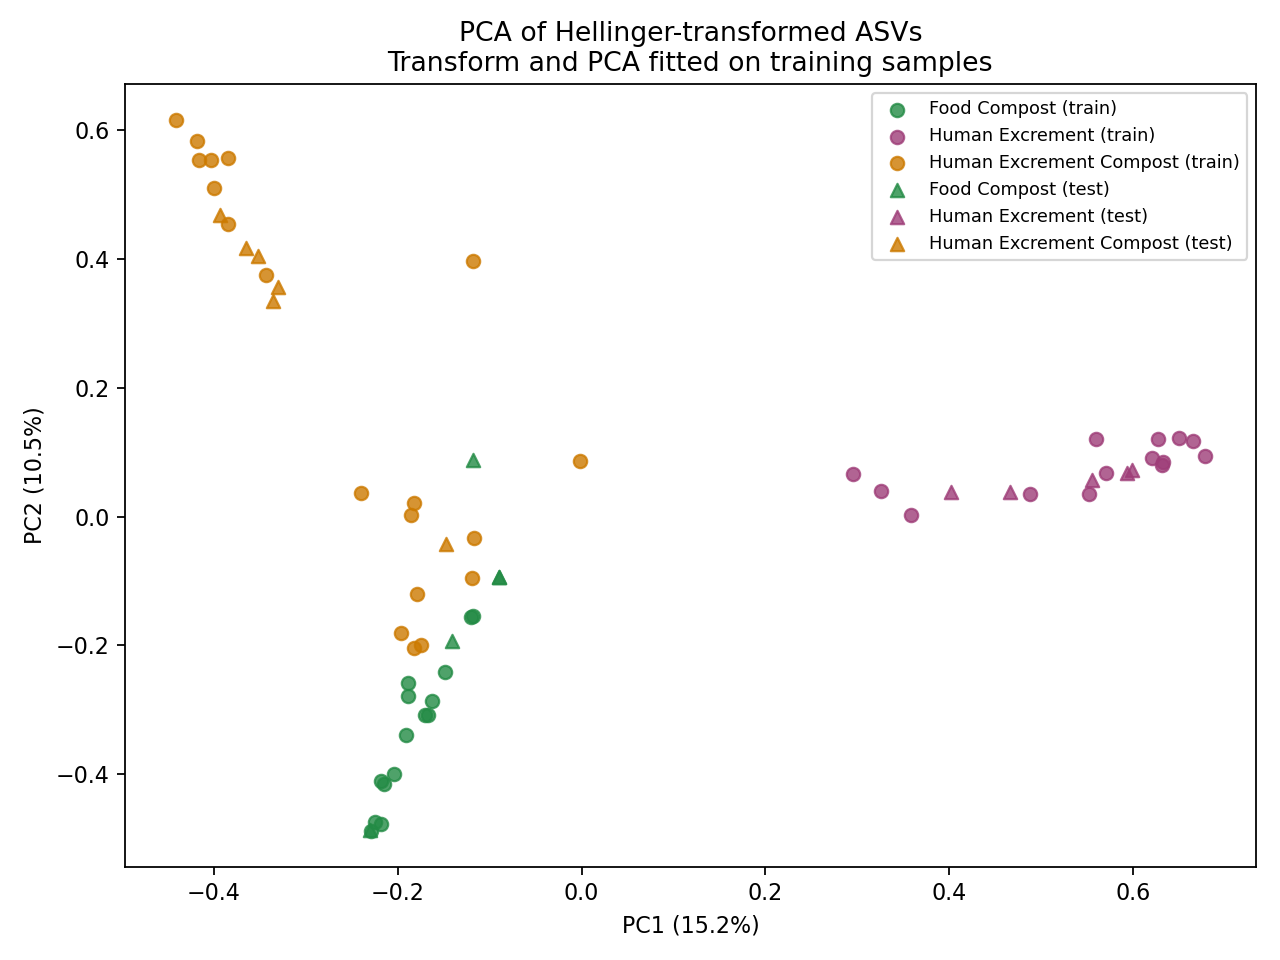

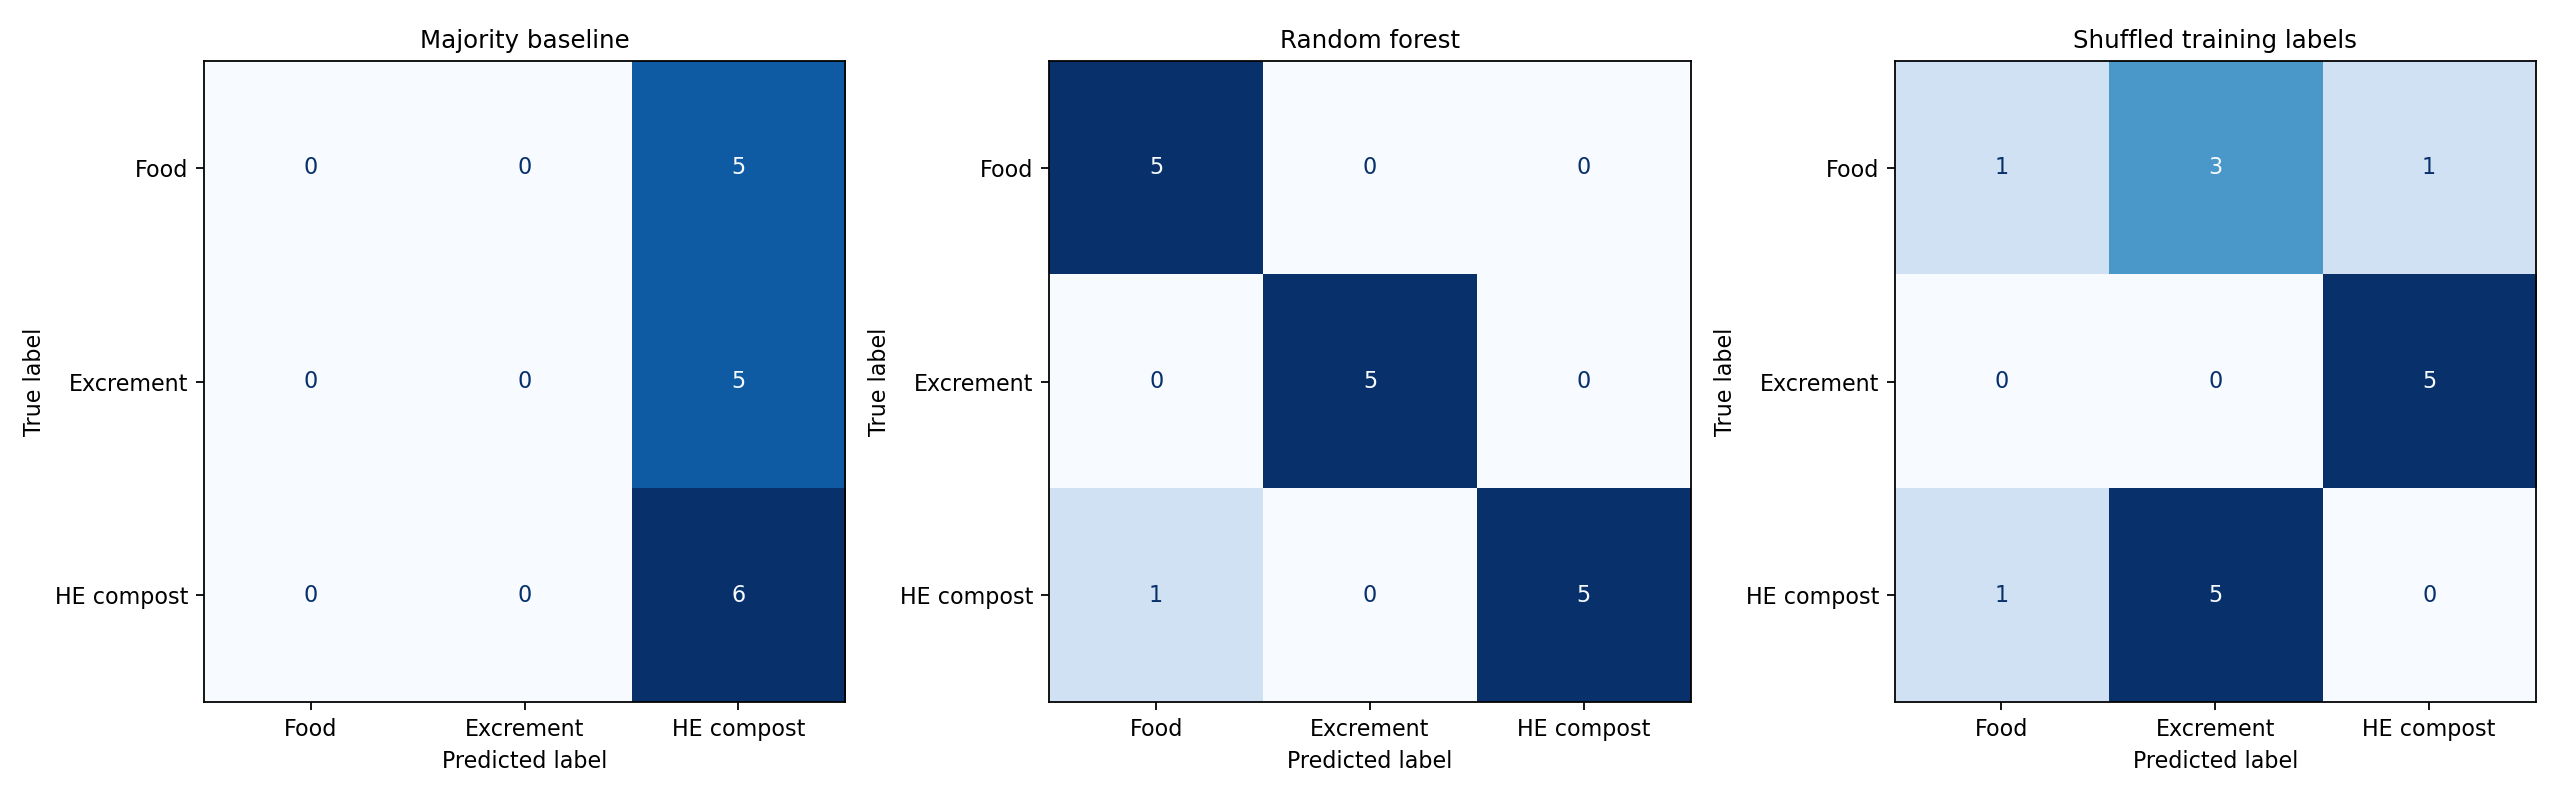

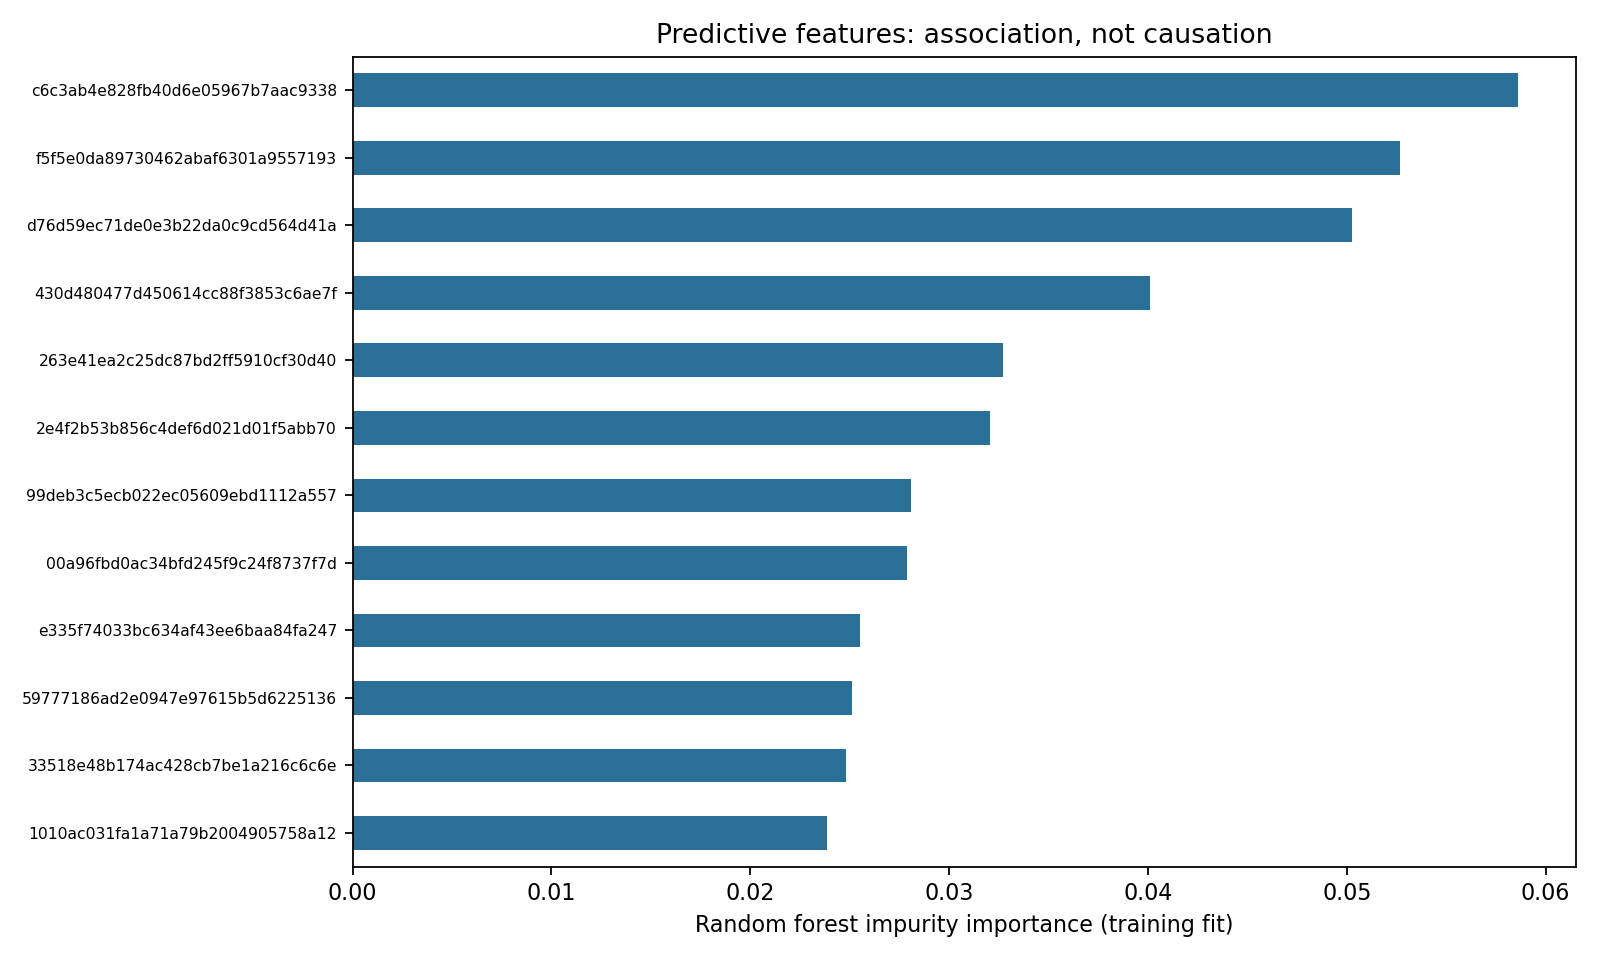

Gut-to-soil sample classification
Samples: 64; ASVs: 1069; train: 48; test: 16
Class counts:
SampleType
Human Excrement Compost    25
Food Compost               20
Human Excrement            19

Majority baseline
                         precision    recall  f1-score   support

           Food Compost       0.00      0.00      0.00         5
        Human Excrement       0.00      0.00      0.00         5
Human Excrement Compost       0.38      1.00      0.55         6

               accuracy                           0.38        16
              macro avg       0.12      0.33      0.18        16
           weighted avg       0.14      0.38      0.20        16


Random forest
                         precision    recall  f1-score   support

           Food Compost       0.83      1.00      0.91         5
        Human Excrement       1.00      1.00      1.00         5
Human Excrement Compost       1.00      0.83      0.91         6

               accuracy                           0.

In [59]:
from IPython.display import display, Image
for name in ['pca.png','confusion-matrices.png','feature-importance.png']:
    path=WORK/'ml'/name
    if path.exists(): display(Image(filename=str(path)))
print((WORK/'ml'/'evaluation.txt').read_text())


### Student interpretation

1. Contrast sequence-level taxonomy classification with sample-level environment classification: observations, features, labels, and reference information.
2. Compare the random forest with the baseline and shuffled-label control. Which errors dominate? Why can accuracy alone be misleading?
3. Does the random split put samples from the same bucket on both sides? How does that affect the claim being evaluated?
4. Compare PCA and PCoA. Does visible separation guarantee accurate prediction on a new biological replicate?
5. Identify one influential ASV. Does importance establish causation? Compare predictive importance with differential abundance, explaining why they need not agree.
6. State two limitations: the small, shallow dataset; compositional features; study dependence; incomplete reference taxonomy; or another evidence-based concern.

**Optional experiment:** change one model setting only after stating a prediction. For genuine model selection, use cross-validation within the training set and reserve a new final test set. Repeatedly optimizing against the displayed test score contaminates that evaluation.

**Your responses:**

**1. Sequence-level vs. sample-level classification.** In taxonomy classification, each observation is one ASV sequence, the features are its k-mers (hashed into 2,048 buckets), and the label is a taxonomic lineage. The model was trained on labeled reference sequences from an external database (GTDB 202.0), so its predictions are limited to the taxa and labels that reference contains. In the environment classification, each observation is one sample, the features are the Hellinger-transformed counts of the 227 ASVs retained by a training-only prevalence filter, and the label is the sample's `SampleType` (Human Excrement, HEC, or Food Compost) from our own metadata. No external reference is used; the model learns only from the 48 training samples in this study, so it can only recognize these three categories and patterns present in this dataset.

**2. Random forest vs. baseline and control.** On the 16 held-out samples, the random forest reached 94% accuracy (15/16), compared with 38% for the majority-class baseline, which predicted HEC for every sample and therefore never identified Food Compost or Human Excrement (recall = 0), and 6% for the shuffled-label control, which shows that performance depends on real label–community associations rather than chance. The only random-forest error was one HEC sample predicted as Food Compost, so errors were concentrated between the two compost types, as I predicted; all Human Excrement samples were correctly classified. Accuracy alone can be misleading because a model can score well by favoring the most common class, as the baseline shows; class-specific recall, precision, and the confusion matrix reveal which classes are being missed. With only 16 test samples, a single misclassification changes accuracy by about 6 percentage points, so these estimates are imprecise.

**3. Bucket overlap.** Yes. The random split placed samples from buckets 5, 7, 10, 12, and 13 in both training and test sets, and the 20 Food Compost samples lacked bucket IDs, so their independence could not be checked. As a result, the 94% holdout accuracy evaluates how well the model classifies new samples from buckets it has already seen, not samples from new composting buckets. Samples from the same bucket share source material and conditions, so the model can benefit from bucket-specific similarity. The separate bucket-grouped 3-fold cross-validation gave lower balanced accuracies (0.75, 0.69, 0.67; mean 0.70), which suggests that generalization to new buckets is weaker, though these numbers come from different folds and are not a direct paired comparison.

**4. PCA vs. PCoA.** PCA was applied directly to the Hellinger-transformed ASV table (fit on the training samples, with test samples projected onto it) and finds linear combinations of ASVs that explain the most Euclidean variance (PC1 15.2%, PC2 10.5%). PCoA, used earlier, starts from a distance matrix (e.g., Bray-Curtis) and finds coordinates that preserve those distances (PC1 25.0%). Both showed Human Excrement separated from the composts on PC1, with HEC and Food Compost closer together but partly separated on PC2. Visible separation does not guarantee accurate prediction on a new biological replicate: these are two-dimensional, unsupervised summaries that capture only part of the variation, the ordination does not test samples from new buckets, and new replicates may differ in ways not represented here. The drop from 94% (random split) to about 70% (bucket-grouped CV) shows this directly.

**5. Influential ASV and causation.** One of the most important features was ASV `263e41ea2c25dc87bd2ff5910cf30d40`, classified as `g__Agathobacter` (Lachnospiraceae; importance ≈ 0.033), a gut-associated genus. Importance does not establish causation: impurity importance measures how much a feature helped the trees split the training samples, which reflects association with the labels, not a causal role in composting. Correlated ASVs can share or swap importance, and these values come from the training fit only. Predictive importance and differential abundance need not agree. This *Agathobacter* ASV was among the most important features, yet ANCOM-BC2 did not find it significantly different between Human Excrement and HEC (log-fold change = +1.03, adjusted q = 1.0). Conversely, the Peptostreptococcaceae ASV `e335f74033bc634af43ee6baa84fa247` (`g__GCA-900066495`) was both important (≈ 0.026) and significant in ANCOM-BC2 (lower in Food Compost than HEC; log-fold change = −1.93, q = 0.004). They can differ because ANCOM-BC2 tests each feature separately for a bias-corrected mean difference with strict multiple-testing correction, while a random forest uses features in combination and rewards any pattern (including presence/absence or interactions) that improves splits. The two analyses also used different filtering and transformations (Hellinger on prevalence-filtered training data vs. ANCOM-BC2's own prevalence filter and bias correction).

**6. Two limitations.** First, the dataset is small and shallow: the classifier was evaluated on only 16 test samples, diversity analyses used 96 reads per sample, and 2 test samples had no counts among the retained ASVs, so all estimates are imprecise and rare taxa are poorly captured. Second, the samples are not independent: multiple samples came from the same buckets and participants, the Food Compost samples came from separate facilities without bucket IDs, and ASV inference used all samples together, so the evaluation is within one study and sequencing run rather than an external validation. In addition, the features are compositional relative abundances, which cannot show changes in absolute abundance.


## Export results before leaving Colab

This archive includes analysis artifacts, plots, scripts, logs, file checksums, and environment information. It excludes the installed environment, the large input read artifact, and reference/trained-classifier artifacts, which can be regenerated or downloaded again. Each downstream QIIME artifact retains its own provenance.


In [60]:
archive=ROOT/'gut_to_soil_results.zip'
excluded={'demux.qza','reference-sequences.qza','reference-taxonomy.qza',
          'suboptimal-16S-rRNA-classifier.qza','teaching-classifier.qza'}
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for directory in [WORK,LOGS,ROOT/'reference-recovery']:
        if directory.exists():
            for p in directory.rglob('*'):
                if p.is_file() and p.name not in excluded:
                    z.write(p,p.relative_to(ROOT))
    for pattern in ['*.json','*.yml','*.py','*.bash']:
        for p in ROOT.glob(pattern): z.write(p,p.name)
print('Archive:',archive,round(archive.stat().st_size/1e6,1),'MB')
from google.colab import files
files.download(str(archive))


Archive: /content/gut_to_soil_student/gut_to_soil_results.zip 49.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Recovery: published visualizations without a working QIIME installation

Run section 1, then this cell if installation or a later computation prevents class from continuing. It downloads **published reference visualizations into a separate folder**, never into the computed analysis. These are not your computed results. Open them in QIIME 2 View. This recovery route supports interpretation, not a claim that the workflow ran successfully. It still requires working internet downloads.


In [ ]:
RECOVERY = False  # change to True only when intentionally using published results
if RECOVERY:
    recovery=ROOT/'reference-recovery'; recovery.mkdir(exist_ok=True)
    names=['demux.qzv','denoising-stats.qzv','asv-table-ms2.qzv','taxa-bar-plots.qzv',
           'alpha-rarefaction.qzv','boots-kmer-diversity/scatter_plot.qzv',
           'ancombc2-barplot.qzv','genus-ancombc2-barplot.qzv']
    failures=[]
    for name in names:
        try: download(BASE+name,recovery/name)
        except Exception as e: failures.append((name,str(e)))
    record('checkpoints.json',dict(step='Reference visualizations only',files=names,failures=failures))
    recovered=ROOT/'published_reference_visualizations.zip'
    with zipfile.ZipFile(recovered,'w') as z:
        for p in recovery.rglob('*.qzv'): z.write(p,p.relative_to(recovery))
    print('PUBLISHED REFERENCE RESULTS — not computed in this runtime. Failures:',failures)
    from google.colab import files
    files.download(str(recovered))
else:
    print('Recovery disabled. Your computed results are unchanged.')


## Final reflection and submission checklist

- [ ] I completed the tutorial commands in order and saved the notebook with outputs.
- [ ] I inspected the quality, taxonomy, ordination, and differential-abundance visualizations.
- [ ] I answered the interpretation prompts using my own results.
- [ ] I identified any downloaded reference results used instead of computed outputs.
- [ ] I downloaded the results ZIP and saved my completed notebook.

**Synthesis (one paragraph):** What evidence supports a difference among microbial communities in the three focal environments? Distinguish descriptive patterns, statistical association, and prediction. State one limitation of this dataset or analysis.

[Write here.]

### If something fails
A placeholder message means you have not pasted the command yet. An unknown option usually indicates the wrong tutorial release or an incomplete paste. Check that you used the Command Line tab, included all output flags, and retained filenames. A failed command prints its log location; preserve the error for your instructor. Do not run downstream commands until their inputs exist. Use the separately labeled recovery plots only if directed.

### Sources
[Gut-to-soil tutorial, QIIME 2 2026.10](https://gut-to-soil-tutorial.readthedocs.io/en/2026.10/), by Caporaso and colleagues, based on the study by Meilander and colleagues. The linked tutorial contains the full explanations and citations. This course scaffold preserves the working instructor notebook’s Colab setup and adds spaces for commands and interpretation. The optional sample-classification extension is course material, separate from the official tutorial.
